In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv
Saving validation.csv to validation.csv


In [ ]:
import pandas as pd

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("validation.csv")
test_df = pd.read_csv("test.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Train: (5808, 4)
Validation: (1245, 4)
Test: (1245, 4)


,abstract_id,medical_abstract,condition_label,condition_name
0,abe3ae23971fd04a,Arterial switch procedure in an adult. The art...,4,cardiovascular diseases
1,d2c1c68e09286d2e,The effects of synthetic human secretin on cal...,2,digestive system diseases
2,46c97fb4a9269cf5,Immunological identification and distribution ...,1,neoplasms
3,b56c4e396fd6ba66,Isotonic high-sodium oral rehydration solution...,5,general pathological conditions
4,58ba7bfb70d8111f,Penetrating keratoplasty for keratoconus: comp...,5,general pathological conditions


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Chosen before model comparison because the classes are imbalanced.
PRIMARY_METRIC = "Macro F1"

def evaluate_model(name, y_true, y_pred):
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }
    return results

print("Primary metric:", PRIMARY_METRIC)

Primary metric: Macro F1


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    max_features=30000,
    ngram_range=(1, 2)
)

X_train = tfidf.fit_transform(train_df["medical_abstract"])
X_val = tfidf.transform(val_df["medical_abstract"])

y_train = train_df["condition_label"]
y_val = val_df["condition_label"]

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)

Training matrix: (5808, 30000)
Validation matrix: (1245, 30000)


In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_predictions = nb_model.predict(X_val)

nb_results = evaluate_model(
    "Multinomial Naive Bayes",
    y_val,
    nb_predictions
)

print("Validation metrics:")
for metric, value in nb_results.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.6f}")

print("\nClassification report:")
print(classification_report(y_val, nb_predictions, digits=4))

Validation metrics:
Model: Multinomial Naive Bayes
Accuracy: 0.675502
Macro Precision: 0.802957
Macro Recall: 0.522456
Macro F1: 0.484887
Weighted F1: 0.614248

Classification report:
              precision    recall  f1-score   support

           1     0.8070    0.9149    0.8575       329
           2     1.0000    0.0095    0.0189       105
           3     0.9000    0.0570    0.1071       158
           4     0.7968    0.8537    0.8243       294
           5     0.5110    0.7772    0.6166       359

    accuracy                         0.6755      1245
   macro avg     0.8030    0.5225    0.4849      1245
weighted avg     0.7473    0.6755    0.6142      1245



In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight=None,
    random_state=42
)

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_val)

lr_results = evaluate_model(
    "Logistic Regression",
    y_val,
    lr_predictions
)

print("Validation metrics:")
for metric, value in lr_results.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.6f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    lr_predictions,
    digits=4
))

Validation metrics:
Model: Logistic Regression
Accuracy: 0.783133
Macro Precision: 0.824221
Macro Recall: 0.729622
Macro F1: 0.760489
Weighted F1: 0.781871

Classification report:
              precision    recall  f1-score   support

           1     0.8727    0.8754    0.8741       329
           2     0.9062    0.5524    0.6864       105
           3     0.8462    0.5570    0.6718       158
           4     0.8610    0.8639    0.8625       294
           5     0.6350    0.7994    0.7078       359

    accuracy                         0.7831      1245
   macro avg     0.8242    0.7296    0.7605      1245
weighted avg     0.8009    0.7831    0.7819      1245



In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

svm_predictions = svm_model.predict(X_val)

svm_results = evaluate_model(
    "Linear SVM",
    y_val,
    svm_predictions
)

print("Validation metrics:")
for metric, value in svm_results.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.6f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    svm_predictions,
    digits=4
))

Validation metrics:
Model: Linear SVM
Accuracy: 0.811245
Macro Precision: 0.824333
Macro Recall: 0.798464
Macro F1: 0.809953
Weighted F1: 0.811463

Classification report:
              precision    recall  f1-score   support

           1     0.8818    0.8845    0.8832       329
           2     0.8830    0.7905    0.8342       105
           3     0.7956    0.6899    0.7390       158
           4     0.8633    0.8810    0.8721       294
           5     0.6979    0.7465    0.7214       359

    accuracy                         0.8112      1245
   macro avg     0.8243    0.7985    0.8100      1245
weighted avg     0.8136    0.8112    0.8115      1245



In [ ]:
baseline_results = pd.DataFrame([
    nb_results,
    lr_results,
    svm_results
])

baseline_results = baseline_results.sort_values(
    by="Macro F1",
    ascending=False
)

display(baseline_results)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
2,Linear SVM,0.811245,0.824333,0.798464,0.809953,0.811463
1,Logistic Regression,0.783133,0.824221,0.729622,0.760489,0.781871
0,Multinomial Naive Bayes,0.675502,0.802957,0.522456,0.484887,0.614248


In [ ]:
baseline_results.to_csv(
    "baseline_validation_results.csv",
    index=False
)

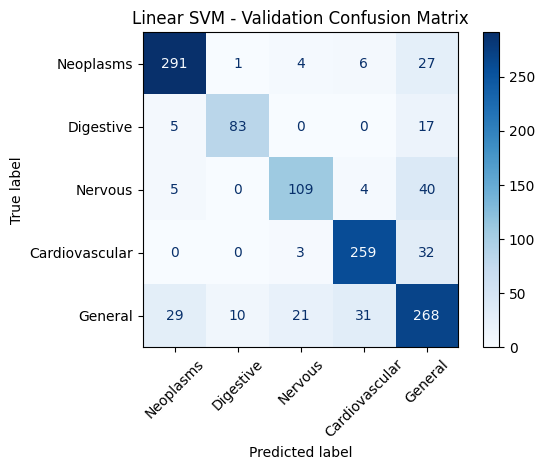

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

labels = [
    "Neoplasms",
    "Digestive",
    "Nervous",
    "Cardiovascular",
    "General"
]

ConfusionMatrixDisplay.from_predictions(
    y_val,
    svm_predictions,
    display_labels=labels,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Linear SVM - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
svm_confusion_matrix = pd.DataFrame(confusion_matrix(y_val, svm_predictions, labels=[1, 2, 3, 4, 5]), index=labels, columns=labels)
print("Rows = actual labels; columns = predicted labels")
print(svm_confusion_matrix.to_string())

Rows = actual labels; columns = predicted labels
                Neoplasms  Digestive  Nervous  Cardiovascular  General
Neoplasms             291          1        4               6       27
Digestive               5         83        0               0       17
Nervous                 5          0      109               4       40
Cardiovascular          0          0        3             259       32
General                29         10       21              31      268


In [ ]:
# Validation-only tuning: the test set is deliberately not referenced.
tuning_records = []

for c_value in [0.1, 0.5, 1.0, 2.0, 5.0]:
    model = LinearSVC(C=c_value, random_state=42)
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    result = evaluate_model("Linear SVM", y_val, predictions)
    result.update({"C": c_value, "Class Weight": "None"})
    tuning_records.append(result)

for c_value in [0.1, 0.5, 1.0, 2.0, 5.0]:
    for class_weight in [None, "balanced"]:
        model = LogisticRegression(
            C=c_value,
            class_weight=class_weight,
            max_iter=1000,
            random_state=42
        )
        model.fit(X_train, y_train)
        predictions = model.predict(X_val)
        result = evaluate_model("Logistic Regression", y_val, predictions)
        result.update({
            "C": c_value,
            "Class Weight": "None" if class_weight is None else class_weight
        })
        tuning_records.append(result)

tuning_results = pd.DataFrame(tuning_records)[[
    "Model", "C", "Class Weight", "Accuracy", "Macro Precision",
    "Macro Recall", "Macro F1", "Weighted F1"
]].sort_values("Macro F1", ascending=False).reset_index(drop=True)

tuning_results.to_csv("tuning_validation_results.csv", index=False)

print("All validation tuning experiments (ranked by Macro F1):")
print(tuning_results.to_string(index=False))
print()
print("Best validation configuration:")
print(tuning_results.iloc[0].to_string())

All validation tuning experiments (ranked by Macro F1):
              Model   C Class Weight  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
Logistic Regression 2.0     balanced  0.820884         0.815469      0.825008  0.820000     0.820884
Logistic Regression 1.0     balanced  0.816064         0.807776      0.821643  0.814205     0.815633
         Linear SVM 0.5         None  0.817671         0.831855      0.800801  0.814178     0.817476
         Linear SVM 1.0         None  0.811245         0.824333      0.798464  0.809953     0.811463
Logistic Regression 5.0     balanced  0.809639         0.806193      0.808124  0.807058     0.809824
         Linear SVM 2.0         None  0.808835         0.818214      0.794615  0.805061     0.808970
Logistic Regression 0.5     balanced  0.805622         0.794701      0.816389  0.804346     0.804701
         Linear SVM 5.0         None  0.806426         0.814910      0.792944  0.802707     0.806264
Logistic Regression 5.0         Non

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Validation-only tuning.
# The test set is NOT used here.

tuning_records = []

# -----------------------------
# 1. Logistic Regression tuning
# -----------------------------
for c_value in [0.1, 0.5, 1.0, 2.0, 5.0]:
    for class_weight in [None, "balanced"]:

        model = LogisticRegression(
            C=c_value,
            class_weight=class_weight,
            max_iter=1000,
            random_state=42
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        result = evaluate_model(
            "Logistic Regression",
            y_val,
            predictions
        )

        result.update({
            "C": c_value,
            "Class Weight": "None" if class_weight is None else "balanced"
        })

        tuning_records.append(result)


# -----------------------------
# 2. Linear SVM tuning
# -----------------------------
for c_value in [0.1, 0.5, 1.0, 2.0, 5.0]:

    model = LinearSVC(
        C=c_value,
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    result = evaluate_model(
        "Linear SVM",
        y_val,
        predictions
    )

    result.update({
        "C": c_value,
        "Class Weight": "None"
    })

    tuning_records.append(result)


# -----------------------------
# 3. Create ranked results table
# -----------------------------
tuning_results = pd.DataFrame(tuning_records)

tuning_results = tuning_results[
    [
        "Model",
        "C",
        "Class Weight",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ]
]

tuning_results = tuning_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)


# -----------------------------
# 4. Save experiment results
# -----------------------------
tuning_results.to_csv(
    "tuning_validation_results.csv",
    index=False
)


# -----------------------------
# 5. Show results
# -----------------------------
print("All validation tuning experiments ranked by Macro F1:\n")
display(tuning_results)

print("\nBest validation configuration:")
display(tuning_results.iloc[[0]])

print("\nSaved as: tuning_validation_results.csv")

All validation tuning experiments ranked by Macro F1:



,Model,C,Class Weight,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Logistic Regression,2.0,balanced,0.820884,0.815469,0.825008,0.820000,0.820884
1,Logistic Regression,1.0,balanced,0.816064,0.807776,0.821643,0.814205,0.815633
2,Linear SVM,0.5,None,0.817671,0.831855,0.800801,0.814178,0.817476
3,Linear SVM,1.0,None,0.811245,0.824333,0.798464,0.809953,0.811463
4,Logistic Regression,5.0,balanced,0.809639,0.806193,0.808124,0.807058,0.809824
5,Linear SVM,2.0,None,0.808835,0.818214,0.794615,0.805061,0.808970
6,Logistic Regression,0.5,balanced,0.805622,0.794701,0.816389,0.804346,0.804701
7,Linear SVM,5.0,None,0.806426,0.814910,0.792944,0.802707,0.806264
8,Logistic Regression,5.0,None,0.804819,0.826840,0.779850,0.799132,0.805608
9,Logistic Regression,2.0,None,0.803213,0.831779,0.766850,0.791165,0.802731



Best validation configuration:


,Model,C,Class Weight,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Logistic Regression,2.0,balanced,0.820884,0.815469,0.825008,0.82,0.820884



Saved as: tuning_validation_results.csv


TRAINING ABSTRACT LENGTH ANALYSIS
---------------------------------------------
Number of abstracts: 5808
Minimum words: 26
Mean words: 181.01
Median words: 177.00
75th percentile: 234
90th percentile: 274
95th percentile: 302
97.5th percentile: 345
99th percentile: 385
Maximum words: 596

Potential truncation by word length
---------------------------------------------
> 128 words: 4279 abstracts (73.67%)
> 256 words:  981 abstracts (16.89%)
> 384 words:   59 abstracts (1.02%)
> 512 words:    2 abstracts (0.03%)


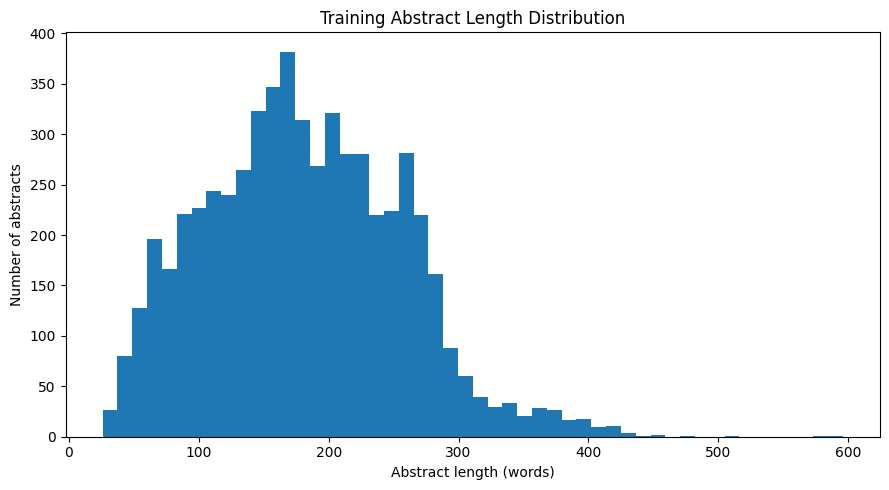

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use training data only for model-readiness decisions
word_lengths = (
    train_df["medical_abstract"]
    .astype(str)
    .str.split()
    .str.len()
)

print("TRAINING ABSTRACT LENGTH ANALYSIS")
print("-" * 45)
print(f"Number of abstracts: {len(word_lengths)}")
print(f"Minimum words: {word_lengths.min()}")
print(f"Mean words: {word_lengths.mean():.2f}")
print(f"Median words: {word_lengths.median():.2f}")
print(f"75th percentile: {np.percentile(word_lengths, 75):.0f}")
print(f"90th percentile: {np.percentile(word_lengths, 90):.0f}")
print(f"95th percentile: {np.percentile(word_lengths, 95):.0f}")
print(f"97.5th percentile: {np.percentile(word_lengths, 97.5):.0f}")
print(f"99th percentile: {np.percentile(word_lengths, 99):.0f}")
print(f"Maximum words: {word_lengths.max()}")

print("\nPotential truncation by word length")
print("-" * 45)

for limit in [128, 256, 384, 512]:
    count = (word_lengths > limit).sum()
    pct = count / len(word_lengths) * 100
    print(f"> {limit:3d} words: {count:4d} abstracts ({pct:.2f}%)")

plt.figure(figsize=(9, 5))
plt.hist(word_lengths, bins=50)
plt.xlabel("Abstract length (words)")
plt.ylabel("Number of abstracts")
plt.title("Training Abstract Length Distribution")
plt.tight_layout()
plt.show()

In [ ]:
length_summary = pd.DataFrame({
    "Statistic": [
        "count",
        "min",
        "mean",
        "median",
        "75th_percentile",
        "90th_percentile",
        "95th_percentile",
        "97.5th_percentile",
        "99th_percentile",
        "max"
    ],
    "Value": [
        len(word_lengths),
        word_lengths.min(),
        word_lengths.mean(),
        word_lengths.median(),
        np.percentile(word_lengths, 75),
        np.percentile(word_lengths, 90),
        np.percentile(word_lengths, 95),
        np.percentile(word_lengths, 97.5),
        np.percentile(word_lengths, 99),
        word_lengths.max()
    ]
})

length_summary.to_csv(
    "abstract_length_analysis.csv",
    index=False
)

display(length_summary)

,Statistic,Value
0,count,5808.000000
1,min,26.000000
2,mean,181.011364
3,median,177.000000
4,75th_percentile,234.000000
5,90th_percentile,274.000000
6,95th_percentile,302.000000
7,97.5th_percentile,345.000000
8,99th_percentile,384.930000
9,max,596.000000


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import time

X_train_text = train_df["medical_abstract"].astype(str)
y_train = train_df["condition_label"]

X_val_text = val_df["medical_abstract"].astype(str)
y_val = val_df["condition_label"]

feature_experiments = {
    "word_unigram": TfidfVectorizer(
        lowercase=True,
        max_features=30000,
        ngram_range=(1, 1)
    ),

    "word_unigram_bigram": TfidfVectorizer(
        lowercase=True,
        max_features=30000,
        ngram_range=(1, 2)
    ),

    "word_plus_char": FeatureUnion([
        (
            "word",
            TfidfVectorizer(
                lowercase=True,
                max_features=30000,
                ngram_range=(1, 2)
            )
        ),
        (
            "char",
            TfidfVectorizer(
                analyzer="char_wb",
                lowercase=True,
                max_features=20000,
                ngram_range=(3, 5)
            )
        )
    ])
}

models = {
    "Logistic Regression": LogisticRegression(
        C=2,
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        C=0.5
    )
}

results = []

for feature_name, vectorizer in feature_experiments.items():

    print(f"\n{'='*60}")
    print(f"FEATURE SET: {feature_name}")
    print("="*60)

    X_train_features = vectorizer.fit_transform(X_train_text)
    X_val_features = vectorizer.transform(X_val_text)

    print("Train shape:", X_train_features.shape)
    print("Validation shape:", X_val_features.shape)

    for model_name, model in models.items():

        start = time.time()

        model.fit(X_train_features, y_train)
        predictions = model.predict(X_val_features)

        elapsed = time.time() - start

        row = {
            "Feature_Set": feature_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro_Precision": precision_score(
                y_val, predictions, average="macro"
            ),
            "Macro_Recall": recall_score(
                y_val, predictions, average="macro"
            ),
            "Macro_F1": f1_score(
                y_val, predictions, average="macro"
            ),
            "Weighted_F1": f1_score(
                y_val, predictions, average="weighted"
            ),
            "Training_Time_Seconds": elapsed
        }

        results.append(row)

        print(
            f"{model_name}: "
            f"Macro F1 = {row['Macro_F1']:.4f}, "
            f"Accuracy = {row['Accuracy']:.4f}"
        )

feature_results_df = pd.DataFrame(results)

feature_results_df = feature_results_df.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

display(feature_results_df)

feature_results_df.to_csv(
    "feature_experiment_results.csv",
    index=False
)


FEATURE SET: word_unigram
Train shape: (5808, 29386)
Validation shape: (1245, 29386)
Logistic Regression: Macro F1 = 0.8203, Accuracy = 0.8217
Linear SVM: Macro F1 = 0.8123, Accuracy = 0.8161

FEATURE SET: word_unigram_bigram
Train shape: (5808, 30000)
Validation shape: (1245, 30000)
Logistic Regression: Macro F1 = 0.8200, Accuracy = 0.8209
Linear SVM: Macro F1 = 0.8142, Accuracy = 0.8177

FEATURE SET: word_plus_char
Train shape: (5808, 50000)
Validation shape: (1245, 50000)
Logistic Regression: Macro F1 = 0.8109, Accuracy = 0.8145
Linear SVM: Macro F1 = 0.8180, Accuracy = 0.8241


,Feature_Set,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,word_unigram,Logistic Regression,0.821687,0.810778,0.832231,0.820326,0.821105,6.940509
1,word_unigram_bigram,Logistic Regression,0.820884,0.815469,0.825008,0.820000,0.820884,6.207720
2,word_plus_char,Linear SVM,0.824096,0.824978,0.812579,0.817993,0.823911,2.072508
3,word_unigram_bigram,Linear SVM,0.817671,0.831855,0.800801,0.814178,0.817476,0.351171
4,word_unigram,Linear SVM,0.816064,0.825243,0.802205,0.812309,0.815798,0.187859
5,word_plus_char,Logistic Regression,0.814458,0.804570,0.818667,0.810904,0.814548,17.402248


BEST CLASSICAL MODEL
TF-IDF Word Unigrams + Logistic Regression

              precision    recall  f1-score   support

           1     0.8947    0.8784    0.8865       329
           2     0.7705    0.8952    0.8282       105
           3     0.7636    0.7975    0.7802       158
           4     0.8624    0.8741    0.8682       294
           5     0.7626    0.7159    0.7385       359

    accuracy                         0.8217      1245
   macro avg     0.8108    0.8322    0.8203      1245
weighted avg     0.8219    0.8217    0.8211      1245



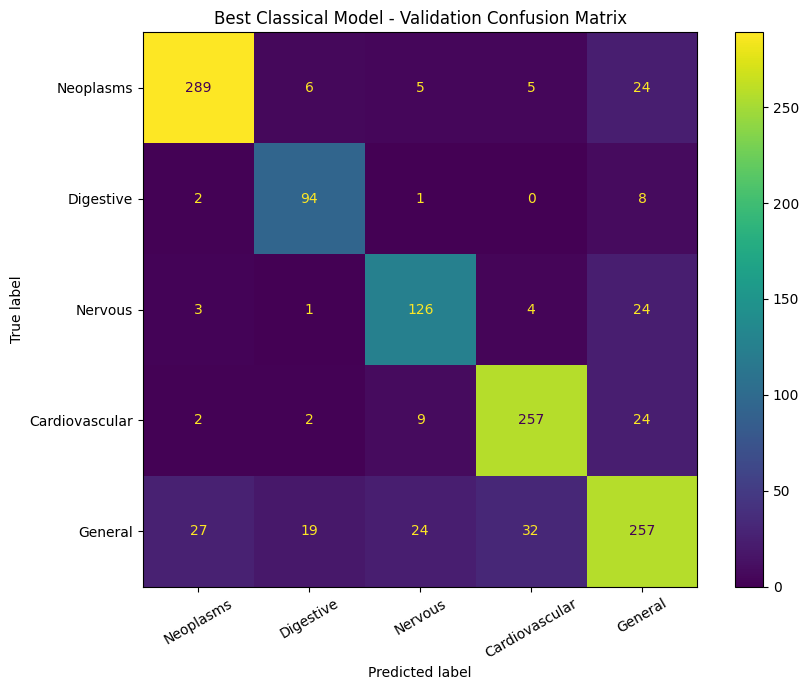

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Winning classical representation
best_vectorizer = TfidfVectorizer(
    lowercase=True,
    max_features=30000,
    ngram_range=(1, 1)
)

X_train_best = best_vectorizer.fit_transform(
    train_df["medical_abstract"].astype(str)
)

X_val_best = best_vectorizer.transform(
    val_df["medical_abstract"].astype(str)
)

# Winning classical model
best_classical_model = LogisticRegression(
    C=2,
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

best_classical_model.fit(
    X_train_best,
    train_df["condition_label"]
)

val_predictions = best_classical_model.predict(X_val_best)

print("BEST CLASSICAL MODEL")
print("TF-IDF Word Unigrams + Logistic Regression")
print()

print(
    classification_report(
        val_df["condition_label"],
        val_predictions,
        digits=4
    )
)

cm = confusion_matrix(
    val_df["condition_label"],
    val_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Neoplasms",
        "Digestive",
        "Nervous",
        "Cardiovascular",
        "General"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=30)
plt.title("Best Classical Model - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# =========================
# PHASE 2 — TEXTCNN
# =========================

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import re
from collections import Counter

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
def simple_tokenize(text):
    text = str(text).lower()
    return re.findall(r"\b\w+\b", text)

train_tokens = [
    simple_tokenize(text)
    for text in train_df["medical_abstract"]
]

word_counter = Counter()
for tokens in train_tokens:
    word_counter.update(tokens)

MIN_FREQ = 2

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, freq in word_counter.items():
    if freq >= MIN_FREQ:
        vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

Vocabulary size: 20301


In [ ]:
MAX_LEN = 384

class MedicalAbstractDataset(Dataset):
    def __init__(self, dataframe, vocab, max_len):
        self.texts = dataframe["medical_abstract"].astype(str).tolist()
        self.labels = dataframe["condition_label"].astype(int).values - 1
        self.vocab = vocab
        self.max_len = max_len

    def encode(self, text):
        tokens = simple_tokenize(text)

        ids = [
            self.vocab.get(token, self.vocab["<UNK>"])
            for token in tokens
        ]

        ids = ids[:self.max_len]

        if len(ids) < self.max_len:
            ids += [self.vocab["<PAD>"]] * (self.max_len - len(ids))

        return torch.tensor(ids, dtype=torch.long)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        x = self.encode(self.texts[idx])
        y = torch.tensor(self.labels[idx], dtype=torch.long)
        return x, y

In [ ]:
BATCH_SIZE = 64

train_dataset = MedicalAbstractDataset(
    train_df,
    vocab,
    MAX_LEN
)

val_dataset = MedicalAbstractDataset(
    val_df,
    vocab,
    MAX_LEN
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 91
Validation batches: 20


In [ ]:
class TextCNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_classes=5,
        num_filters=100,
        filter_sizes=(3, 4, 5),
        dropout=0.5,
        padding_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(
                in_channels=embedding_dim,
                out_channels=num_filters,
                kernel_size=fs
            )
            for fs in filter_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(filter_sizes),
            num_classes
        )

    def forward(self, x):
        # x: [batch_size, seq_len]

        x = self.embedding(x)
        # [batch_size, seq_len, embedding_dim]

        x = x.permute(0, 2, 1)
        # [batch_size, embedding_dim, seq_len]

        conv_outputs = []

        for conv in self.convs:
            c = F.relu(conv(x))
            # [batch_size, num_filters, new_seq_len]

            c = F.max_pool1d(
                c,
                kernel_size=c.shape[2]
            ).squeeze(2)

            conv_outputs.append(c)

        x = torch.cat(conv_outputs, dim=1)

        x = self.dropout(x)

        return self.fc(x)

In [ ]:
torch.manual_seed(42)

model = TextCNN(
    vocab_size=len(vocab),
    embedding_dim=128,
    num_classes=5,
    num_filters=100,
    filter_sizes=(3, 4, 5),
    dropout=0.5
).to(device)

print(model)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

TextCNN(
  (embedding): Embedding(20301, 128, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(128, 100, kernel_size=(3,), stride=(1,))
    (1): Conv1d(128, 100, kernel_size=(4,), stride=(1,))
    (2): Conv1d(128, 100, kernel_size=(5,), stride=(1,))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=300, out_features=5, bias=True)
)

Total parameters: 2,753,933
Trainable parameters: 2,753,933


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

EPOCHS = 10

In [ ]:
from copy import deepcopy

best_val_f1 = -1
best_model_state = None

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    # -------------------------
    # TRAIN
    # -------------------------
    model.train()

    total_train_loss = 0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(x_batch)

        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(x_batch)

            loss = criterion(logits, y_batch)
            total_val_loss += loss.item()

            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)

    # Save best model by Macro F1
    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_model_state = deepcopy(model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print("\nBest Validation Macro F1:", round(best_val_f1, 4))

Epoch 01/10 | Train Loss: 1.6681 | Val Loss: 1.2483 | Val Acc: 0.5518 | Val Macro F1: 0.3879
Epoch 02/10 | Train Loss: 1.2020 | Val Loss: 0.9983 | Val Acc: 0.6378 | Val Macro F1: 0.4907
Epoch 03/10 | Train Loss: 0.9967 | Val Loss: 0.9141 | Val Acc: 0.6498 | Val Macro F1: 0.5322
Epoch 04/10 | Train Loss: 0.8949 | Val Loss: 0.8419 | Val Acc: 0.6594 | Val Macro F1: 0.5484
Epoch 05/10 | Train Loss: 0.8031 | Val Loss: 0.8181 | Val Acc: 0.6803 | Val Macro F1: 0.5782
Epoch 06/10 | Train Loss: 0.7048 | Val Loss: 0.7555 | Val Acc: 0.7277 | Val Macro F1: 0.6833
Epoch 07/10 | Train Loss: 0.6530 | Val Loss: 0.7197 | Val Acc: 0.7382 | Val Macro F1: 0.7179
Epoch 08/10 | Train Loss: 0.5697 | Val Loss: 0.6851 | Val Acc: 0.7454 | Val Macro F1: 0.7285
Epoch 09/10 | Train Loss: 0.4962 | Val Loss: 0.6876 | Val Acc: 0.7751 | Val Macro F1: 0.7695
Epoch 10/10 | Train Loss: 0.4518 | Val Loss: 0.6568 | Val Acc: 0.7655 | Val Macro F1: 0.7568

Best Validation Macro F1: 0.7695


In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

for epoch in range(10, 20):

    model.train()
    total_train_loss = 0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(x_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(x_batch)
            loss = criterion(logits, y_batch)

            total_val_loss += loss.item()

            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    scheduler.step(val_macro_f1)

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_model_state = deepcopy(model.state_dict())

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch + 1:02d}/20 | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f} | "
        f"LR: {current_lr:.6f}"
    )

print("\nBest Validation Macro F1:", round(best_val_f1, 4))

Epoch 11/20 | Train Loss: 0.4087 | Val Loss: 0.6601 | Val Acc: 0.7711 | Val Macro F1: 0.7561 | LR: 0.001000
Epoch 12/20 | Train Loss: 0.3505 | Val Loss: 0.6799 | Val Acc: 0.7462 | Val Macro F1: 0.7262 | LR: 0.001000
Epoch 13/20 | Train Loss: 0.2990 | Val Loss: 0.6577 | Val Acc: 0.7631 | Val Macro F1: 0.7480 | LR: 0.001000
Epoch 14/20 | Train Loss: 0.2606 | Val Loss: 0.6713 | Val Acc: 0.7622 | Val Macro F1: 0.7426 | LR: 0.000500
Epoch 15/20 | Train Loss: 0.2169 | Val Loss: 0.6488 | Val Acc: 0.7703 | Val Macro F1: 0.7625 | LR: 0.000500
Epoch 16/20 | Train Loss: 0.1817 | Val Loss: 0.6528 | Val Acc: 0.7767 | Val Macro F1: 0.7732 | LR: 0.000500
Epoch 17/20 | Train Loss: 0.1571 | Val Loss: 0.6673 | Val Acc: 0.7663 | Val Macro F1: 0.7519 | LR: 0.000500
Epoch 18/20 | Train Loss: 0.1440 | Val Loss: 0.6643 | Val Acc: 0.7767 | Val Macro F1: 0.7703 | LR: 0.000500
Epoch 19/20 | Train Loss: 0.1264 | Val Loss: 0.6755 | Val Acc: 0.7663 | Val Macro F1: 0.7536 | LR: 0.000250
Epoch 20/20 | Train Loss: 0.

TEXTCNN — BEST VALIDATION CHECKPOINT

              precision    recall  f1-score   support

           1     0.8833    0.8511    0.8669       329
           2     0.8736    0.7238    0.7917       105
           3     0.7203    0.6519    0.6844       158
           4     0.8295    0.8605    0.8447       294
           5     0.6489    0.7103    0.6782       359

    accuracy                         0.7767      1245
   macro avg     0.7911    0.7595    0.7732      1245
weighted avg     0.7815    0.7767    0.7777      1245



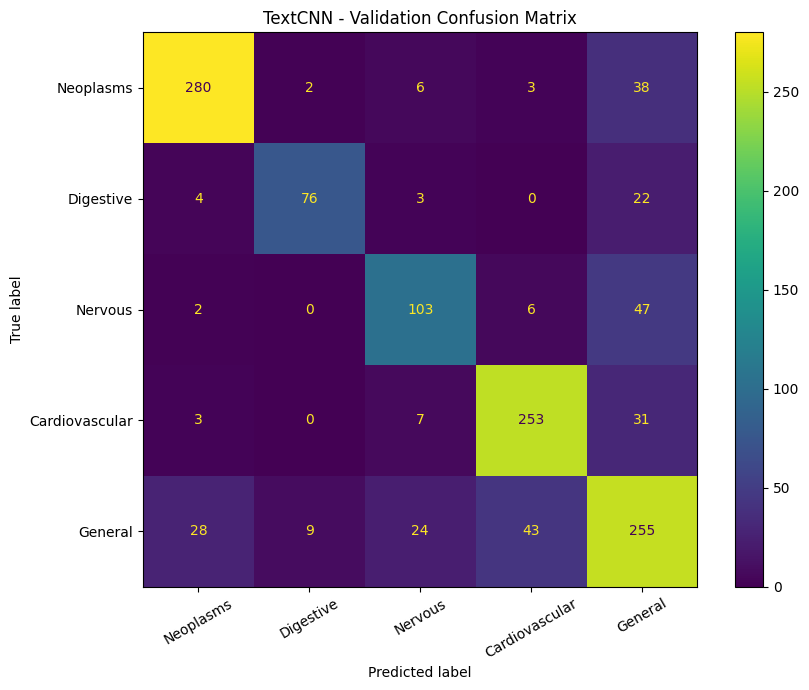

In [ ]:
# Restore best TextCNN checkpoint
model.load_state_dict(best_model_state)
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for x_batch, y_batch in val_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(x_batch)
        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

# Convert labels back from 0-4 to 1-5
all_preds_original = np.array(all_preds) + 1
all_labels_original = np.array(all_labels) + 1

print("TEXTCNN — BEST VALIDATION CHECKPOINT")
print()

print(
    classification_report(
        all_labels_original,
        all_preds_original,
        digits=4
    )
)

cm = confusion_matrix(
    all_labels_original,
    all_preds_original
)

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Neoplasms",
        "Digestive",
        "Nervous",
        "Cardiovascular",
        "General"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=30)
plt.title("TextCNN - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

train_labels_zero_based = (
    train_df["condition_label"].astype(int).values - 1
)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(5),
    y=train_labels_zero_based
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)

Class weights: tensor([0.7563, 2.3755, 1.5826, 0.8460, 0.6931], device='cuda:0')


In [ ]:
torch.manual_seed(42)

weighted_model = TextCNN(
    vocab_size=len(vocab),
    embedding_dim=128,
    num_classes=5,
    num_filters=100,
    filter_sizes=(3, 4, 5),
    dropout=0.5
).to(device)

weighted_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

weighted_optimizer = torch.optim.Adam(
    weighted_model.parameters(),
    lr=1e-3
)

EPOCHS = 20

In [ ]:
from copy import deepcopy

best_weighted_f1 = -1
best_weighted_state = None

for epoch in range(EPOCHS):

    weighted_model.train()
    total_train_loss = 0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        weighted_optimizer.zero_grad()

        logits = weighted_model(x_batch)

        loss = weighted_criterion(
            logits,
            y_batch
        )

        loss.backward()
        weighted_optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    weighted_model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for x_batch, y_batch in val_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            logits = weighted_model(x_batch)

            loss = weighted_criterion(
                logits,
                y_batch
            )

            total_val_loss += loss.item()

            preds = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

    avg_val_loss = total_val_loss / len(val_loader)

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    if val_macro_f1 > best_weighted_f1:
        best_weighted_f1 = val_macro_f1
        best_weighted_state = deepcopy(
            weighted_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest Weighted TextCNN Validation Macro F1:",
    round(best_weighted_f1, 4)
)

Epoch 01/20 | Train Loss: 1.8005 | Val Loss: 1.3996 | Val Acc: 0.5382 | Val Macro F1: 0.4026
Epoch 02/20 | Train Loss: 1.3457 | Val Loss: 1.1103 | Val Acc: 0.5325 | Val Macro F1: 0.5055
Epoch 03/20 | Train Loss: 1.0937 | Val Loss: 0.9647 | Val Acc: 0.6241 | Val Macro F1: 0.6235
Epoch 04/20 | Train Loss: 0.9549 | Val Loss: 0.8607 | Val Acc: 0.7092 | Val Macro F1: 0.7028
Epoch 05/20 | Train Loss: 0.8235 | Val Loss: 0.8554 | Val Acc: 0.7108 | Val Macro F1: 0.7032
Epoch 06/20 | Train Loss: 0.7238 | Val Loss: 0.7715 | Val Acc: 0.7470 | Val Macro F1: 0.7444
Epoch 07/20 | Train Loss: 0.6769 | Val Loss: 0.7284 | Val Acc: 0.7438 | Val Macro F1: 0.7372
Epoch 08/20 | Train Loss: 0.5879 | Val Loss: 0.6979 | Val Acc: 0.7317 | Val Macro F1: 0.7352
Epoch 09/20 | Train Loss: 0.5116 | Val Loss: 0.6866 | Val Acc: 0.7325 | Val Macro F1: 0.7240
Epoch 10/20 | Train Loss: 0.4636 | Val Loss: 0.6601 | Val Acc: 0.7614 | Val Macro F1: 0.7570
Epoch 11/20 | Train Loss: 0.4271 | Val Loss: 0.6685 | Val Acc: 0.7727 

WEIGHTED TEXTCNN — BEST VALIDATION CHECKPOINT

              precision    recall  f1-score   support

           1     0.8889    0.8511    0.8696       329
           2     0.8571    0.7429    0.7959       105
           3     0.7571    0.6709    0.7114       158
           4     0.8943    0.8061    0.8479       294
           5     0.6406    0.7744    0.7011       359

    accuracy                         0.7863      1245
   macro avg     0.8076    0.7691    0.7852      1245
weighted avg     0.7992    0.7863    0.7896      1245



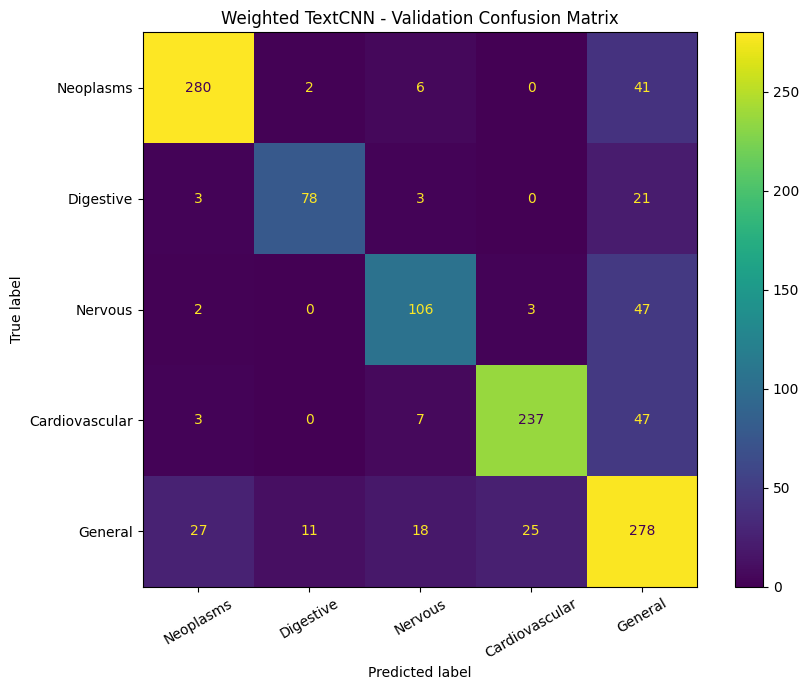

In [ ]:
weighted_model.load_state_dict(best_weighted_state)
weighted_model.eval()

weighted_preds = []
weighted_labels = []

with torch.no_grad():
    for x_batch, y_batch in val_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        logits = weighted_model(x_batch)
        preds = torch.argmax(logits, dim=1)

        weighted_preds.extend(preds.cpu().numpy())
        weighted_labels.extend(y_batch.cpu().numpy())

weighted_preds_original = np.array(weighted_preds) + 1
weighted_labels_original = np.array(weighted_labels) + 1

print("WEIGHTED TEXTCNN — BEST VALIDATION CHECKPOINT\n")

print(
    classification_report(
        weighted_labels_original,
        weighted_preds_original,
        digits=4
    )
)

cm = confusion_matrix(
    weighted_labels_original,
    weighted_preds_original
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Neoplasms",
        "Digestive",
        "Nervous",
        "Cardiovascular",
        "General"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=30)
plt.title("Weighted TextCNN - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
torch.manual_seed(42)

cnn_variant = TextCNN(
    vocab_size=len(vocab),
    embedding_dim=128,
    num_classes=5,
    num_filters=100,
    filter_sizes=(2, 3, 4, 5),
    dropout=0.5
).to(device)

variant_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

variant_optimizer = torch.optim.Adam(
    cnn_variant.parameters(),
    lr=1e-3
)

print(cnn_variant)

print(
    "\nTrainable parameters:",
    f"{sum(p.numel() for p in cnn_variant.parameters() if p.requires_grad):,}"
)

TextCNN(
  (embedding): Embedding(20301, 128, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(128, 100, kernel_size=(2,), stride=(1,))
    (1): Conv1d(128, 100, kernel_size=(3,), stride=(1,))
    (2): Conv1d(128, 100, kernel_size=(4,), stride=(1,))
    (3): Conv1d(128, 100, kernel_size=(5,), stride=(1,))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=400, out_features=5, bias=True)
)

Trainable parameters: 2,780,133


In [ ]:
best_variant_f1 = -1
best_variant_state = None

for epoch in range(20):

    # TRAIN
    cnn_variant.train()
    total_train_loss = 0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        variant_optimizer.zero_grad()

        logits = cnn_variant(x_batch)

        loss = variant_criterion(
            logits,
            y_batch
        )

        loss.backward()
        variant_optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # VALIDATION
    cnn_variant.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            logits = cnn_variant(x_batch)

            loss = variant_criterion(
                logits,
                y_batch
            )

            total_val_loss += loss.item()

            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    if val_macro_f1 > best_variant_f1:
        best_variant_f1 = val_macro_f1
        best_variant_state = deepcopy(
            cnn_variant.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/20 | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest CNN Variant Validation Macro F1:",
    round(best_variant_f1, 4)
)

Epoch 01/20 | Train Loss: 1.7740 | Val Loss: 1.3816 | Val Acc: 0.3663 | Val Macro F1: 0.3592
Epoch 02/20 | Train Loss: 1.2936 | Val Loss: 1.0502 | Val Acc: 0.6659 | Val Macro F1: 0.6424
Epoch 03/20 | Train Loss: 1.0555 | Val Loss: 0.9110 | Val Acc: 0.6586 | Val Macro F1: 0.6652
Epoch 04/20 | Train Loss: 0.8925 | Val Loss: 0.8249 | Val Acc: 0.6731 | Val Macro F1: 0.6617
Epoch 05/20 | Train Loss: 0.7935 | Val Loss: 0.7688 | Val Acc: 0.7277 | Val Macro F1: 0.7319
Epoch 06/20 | Train Loss: 0.7114 | Val Loss: 0.7405 | Val Acc: 0.7478 | Val Macro F1: 0.7487
Epoch 07/20 | Train Loss: 0.6084 | Val Loss: 0.7253 | Val Acc: 0.7446 | Val Macro F1: 0.7460
Epoch 08/20 | Train Loss: 0.5571 | Val Loss: 0.6639 | Val Acc: 0.7398 | Val Macro F1: 0.7414
Epoch 09/20 | Train Loss: 0.4959 | Val Loss: 0.7247 | Val Acc: 0.7430 | Val Macro F1: 0.7376
Epoch 10/20 | Train Loss: 0.4421 | Val Loss: 0.6462 | Val Acc: 0.7647 | Val Macro F1: 0.7652
Epoch 11/20 | Train Loss: 0.3896 | Val Loss: 0.6155 | Val Acc: 0.7783 

In [ ]:
class BiLSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_classes=5,
        num_layers=1,
        dropout=0.5,
        padding_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):
        x = self.embedding(x)

        output, (hidden, cell) = self.lstm(x)

        # Last forward + last backward hidden states
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        x = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        x = self.dropout(x)

        return self.fc(x)

In [ ]:
# ==========================================================
# PHASE 3 — BiLSTM
# ==========================================================

## Objective
#Train a Bidirectional LSTM classifier to test whether sequential context
#and bidirectional information improve medical abstract classification
#compared with the classical ML and TextCNN baselines.

## Previous Best Results
#- Best Classical Model: TF-IDF + Balanced Logistic Regression
 # - Validation Macro F1: 0.8203

#- Best TextCNN:
 # - Weighted TextCNN
  #- Filter sizes: (2, 3, 4, 5)
   #- Validation Macro F1: 0.7863

## Main Evaluation Metric
#Macro F1

In [ ]:
torch.manual_seed(42)

bilstm_model = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_classes=5,
    num_layers=1,
    dropout=0.5
).to(device)

print(bilstm_model)

total_params = sum(
    p.numel()
    for p in bilstm_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in bilstm_model.parameters()
    if p.requires_grad
)

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

BiLSTMClassifier(
  (embedding): Embedding(20301, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=5, bias=True)
)

Total parameters: 2,864,005
Trainable parameters: 2,864,005


In [ ]:
# BiLSTM DataLoaders
BILSTM_BATCH_SIZE = 32

bilstm_train_loader = DataLoader(
    train_dataset,
    batch_size=BILSTM_BATCH_SIZE,
    shuffle=True
)

bilstm_val_loader = DataLoader(
    val_dataset,
    batch_size=BILSTM_BATCH_SIZE,
    shuffle=False
)

print("BiLSTM train batches:", len(bilstm_train_loader))
print("BiLSTM validation batches:", len(bilstm_val_loader))

BiLSTM train batches: 182
BiLSTM validation batches: 39


In [ ]:
bilstm_criterion = nn.CrossEntropyLoss()

bilstm_optimizer = torch.optim.Adam(
    bilstm_model.parameters(),
    lr=1e-3
)

BILSTM_EPOCHS = 15

In [ ]:
from copy import deepcopy

best_bilstm_f1 = -1
best_bilstm_state = None

bilstm_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(BILSTM_EPOCHS):

    # --------------------
    # TRAIN
    # --------------------
    bilstm_model.train()
    total_train_loss = 0

    for x_batch, y_batch in bilstm_train_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        bilstm_optimizer.zero_grad()

        logits = bilstm_model(x_batch)

        loss = bilstm_criterion(
            logits,
            y_batch
        )

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            bilstm_model.parameters(),
            max_norm=1.0
        )

        bilstm_optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(bilstm_train_loader)
    )

    # --------------------
    # VALIDATION
    # --------------------
    bilstm_model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for x_batch, y_batch in bilstm_val_loader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            logits = bilstm_model(x_batch)

            loss = bilstm_criterion(
                logits,
                y_batch
            )

            total_val_loss += loss.item()

            preds = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

    avg_val_loss = (
        total_val_loss / len(bilstm_val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    bilstm_history["train_loss"].append(
        avg_train_loss
    )

    bilstm_history["val_loss"].append(
        avg_val_loss
    )

    bilstm_history["val_accuracy"].append(
        val_accuracy
    )

    bilstm_history["val_macro_f1"].append(
        val_macro_f1
    )

    if val_macro_f1 > best_bilstm_f1:

        best_bilstm_f1 = val_macro_f1

        best_bilstm_state = deepcopy(
            bilstm_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{BILSTM_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest BiLSTM Validation Macro F1:",
    round(best_bilstm_f1, 4)
)

Epoch 01/15 | Train Loss: 1.4538 | Val Loss: 1.2485 | Val Acc: 0.5213 | Val Macro F1: 0.3549
Epoch 02/15 | Train Loss: 1.0627 | Val Loss: 1.0766 | Val Acc: 0.6000 | Val Macro F1: 0.4111
Epoch 03/15 | Train Loss: 0.8738 | Val Loss: 1.0141 | Val Acc: 0.6249 | Val Macro F1: 0.4739
Epoch 04/15 | Train Loss: 0.6976 | Val Loss: 0.9444 | Val Acc: 0.6522 | Val Macro F1: 0.5759
Epoch 05/15 | Train Loss: 0.5181 | Val Loss: 0.9163 | Val Acc: 0.6643 | Val Macro F1: 0.6254
Epoch 06/15 | Train Loss: 0.3635 | Val Loss: 1.0134 | Val Acc: 0.6779 | Val Macro F1: 0.6481
Epoch 07/15 | Train Loss: 0.2475 | Val Loss: 0.9668 | Val Acc: 0.7020 | Val Macro F1: 0.6702
Epoch 08/15 | Train Loss: 0.1573 | Val Loss: 1.1246 | Val Acc: 0.6771 | Val Macro F1: 0.6552
Epoch 09/15 | Train Loss: 0.1009 | Val Loss: 1.3764 | Val Acc: 0.6867 | Val Macro F1: 0.6571
Epoch 10/15 | Train Loss: 0.0620 | Val Loss: 1.3725 | Val Acc: 0.6980 | Val Macro F1: 0.6768
Epoch 11/15 | Train Loss: 0.0480 | Val Loss: 1.4474 | Val Acc: 0.6964 

In [ ]:
class MedicalAbstractDatasetWithLength(Dataset):
    def __init__(self, dataframe, vocab, max_len):
        self.texts = dataframe["medical_abstract"].astype(str).tolist()
        self.labels = dataframe["condition_label"].astype(int).values - 1
        self.vocab = vocab
        self.max_len = max_len

    def encode(self, text):
        tokens = simple_tokenize(text)

        ids = [
            self.vocab.get(token, self.vocab["<UNK>"])
            for token in tokens
        ]

        ids = ids[:self.max_len]

        length = len(ids)

        if length < self.max_len:
            ids += [self.vocab["<PAD>"]] * (self.max_len - length)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(length, dtype=torch.long)
        )

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        x, length = self.encode(self.texts[idx])
        y = torch.tensor(self.labels[idx], dtype=torch.long)

        return x, length, y

In [ ]:
bilstm_train_dataset = MedicalAbstractDatasetWithLength(
    train_df, vocab, MAX_LEN
)

bilstm_val_dataset = MedicalAbstractDatasetWithLength(
    val_df, vocab, MAX_LEN
)

bilstm_train_loader = DataLoader(
    bilstm_train_dataset,
    batch_size=32,
    shuffle=True
)

bilstm_val_loader = DataLoader(
    bilstm_val_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:
class BiLSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_classes=5,
        dropout=0.5,
        padding_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x, lengths):

        x = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        x = torch.cat(
            [forward_hidden, backward_hidden],
            dim=1
        )

        x = self.dropout(x)

        return self.fc(x)

In [ ]:
torch.manual_seed(42)

bilstm_model = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_classes=5,
    dropout=0.5
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    bilstm_model.parameters(),
    lr=1e-3
)

In [ ]:
for x_batch, lengths, y_batch in bilstm_train_loader:

    x_batch = x_batch.to(device)
    lengths = lengths.to(device)
    y_batch = y_batch.to(device)

    logits = bilstm_model(x_batch, lengths)

In [ ]:
from copy import deepcopy

best_bilstm_f1 = -1
best_bilstm_state = None

BILSTM_EPOCHS = 15

for epoch in range(BILSTM_EPOCHS):

    # --------------------
    # TRAIN
    # --------------------
    bilstm_model.train()
    total_train_loss = 0

    for x_batch, lengths, y_batch in bilstm_train_loader:

        x_batch = x_batch.to(device)
        lengths = lengths.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = bilstm_model(
            x_batch,
            lengths
        )

        loss = criterion(
            logits,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            bilstm_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(bilstm_train_loader)
    )

    # --------------------
    # VALIDATION
    # --------------------
    bilstm_model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for x_batch, lengths, y_batch in bilstm_val_loader:

            x_batch = x_batch.to(device)
            lengths = lengths.to(device)
            y_batch = y_batch.to(device)

            logits = bilstm_model(
                x_batch,
                lengths
            )

            loss = criterion(
                logits,
                y_batch
            )

            total_val_loss += loss.item()

            preds = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

    avg_val_loss = (
        total_val_loss / len(bilstm_val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    if val_macro_f1 > best_bilstm_f1:
        best_bilstm_f1 = val_macro_f1

        best_bilstm_state = deepcopy(
            bilstm_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{BILSTM_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest Corrected BiLSTM Validation Macro F1:",
    round(best_bilstm_f1, 4)
)

Epoch 01/15 | Train Loss: 1.4661 | Val Loss: 1.2537 | Val Acc: 0.5036 | Val Macro F1: 0.3391
Epoch 02/15 | Train Loss: 1.0728 | Val Loss: 1.0438 | Val Acc: 0.6064 | Val Macro F1: 0.4760
Epoch 03/15 | Train Loss: 0.8211 | Val Loss: 1.0057 | Val Acc: 0.6145 | Val Macro F1: 0.5160
Epoch 04/15 | Train Loss: 0.5936 | Val Loss: 0.9946 | Val Acc: 0.6522 | Val Macro F1: 0.5645
Epoch 05/15 | Train Loss: 0.4001 | Val Loss: 0.9828 | Val Acc: 0.6683 | Val Macro F1: 0.6251
Epoch 06/15 | Train Loss: 0.2395 | Val Loss: 1.0557 | Val Acc: 0.6763 | Val Macro F1: 0.6280
Epoch 07/15 | Train Loss: 0.1202 | Val Loss: 1.2539 | Val Acc: 0.6651 | Val Macro F1: 0.6340
Epoch 08/15 | Train Loss: 0.0573 | Val Loss: 1.3478 | Val Acc: 0.6771 | Val Macro F1: 0.6330
Epoch 09/15 | Train Loss: 0.0346 | Val Loss: 1.4143 | Val Acc: 0.6908 | Val Macro F1: 0.6360
Epoch 10/15 | Train Loss: 0.0151 | Val Loss: 1.3794 | Val Acc: 0.6827 | Val Macro F1: 0.6480
Epoch 11/15 | Train Loss: 0.0122 | Val Loss: 1.5045 | Val Acc: 0.6900 

In [ ]:
weighted_bilstm_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

torch.manual_seed(42)

weighted_bilstm_model = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_classes=5,
    dropout=0.5
).to(device)

weighted_bilstm_optimizer = torch.optim.Adam(
    weighted_bilstm_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [ ]:
from copy import deepcopy

# Fresh weighted BiLSTM model
torch.manual_seed(42)

weighted_bilstm_model = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_classes=5,
    dropout=0.5
).to(device)

weighted_bilstm_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

weighted_bilstm_optimizer = torch.optim.Adam(
    weighted_bilstm_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

WEIGHTED_BILSTM_EPOCHS = 10

best_weighted_bilstm_f1 = -1
best_weighted_bilstm_state = None

for epoch in range(WEIGHTED_BILSTM_EPOCHS):

    # --------------------
    # TRAIN
    # --------------------
    weighted_bilstm_model.train()
    total_train_loss = 0

    for x_batch, lengths, y_batch in bilstm_train_loader:

        x_batch = x_batch.to(device)
        lengths = lengths.to(device)
        y_batch = y_batch.to(device)

        weighted_bilstm_optimizer.zero_grad()

        logits = weighted_bilstm_model(
            x_batch,
            lengths
        )

        loss = weighted_bilstm_criterion(
            logits,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            weighted_bilstm_model.parameters(),
            max_norm=1.0
        )

        weighted_bilstm_optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(bilstm_train_loader)
    )

    # --------------------
    # VALIDATION
    # --------------------
    weighted_bilstm_model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for x_batch, lengths, y_batch in bilstm_val_loader:

            x_batch = x_batch.to(device)
            lengths = lengths.to(device)
            y_batch = y_batch.to(device)

            logits = weighted_bilstm_model(
                x_batch,
                lengths
            )

            loss = weighted_bilstm_criterion(
                logits,
                y_batch
            )

            total_val_loss += loss.item()

            preds = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

    avg_val_loss = (
        total_val_loss / len(bilstm_val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    if val_macro_f1 > best_weighted_bilstm_f1:
        best_weighted_bilstm_f1 = val_macro_f1
        best_weighted_bilstm_state = deepcopy(
            weighted_bilstm_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{WEIGHTED_BILSTM_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest Weighted BiLSTM Validation Macro F1:",
    round(best_weighted_bilstm_f1, 4)
)

Epoch 01/10 | Train Loss: 1.5769 | Val Loss: 1.5342 | Val Acc: 0.2827 | Val Macro F1: 0.2762
Epoch 02/10 | Train Loss: 1.2786 | Val Loss: 1.1635 | Val Acc: 0.5422 | Val Macro F1: 0.4917
Epoch 03/10 | Train Loss: 0.9959 | Val Loss: 1.1014 | Val Acc: 0.5631 | Val Macro F1: 0.5219
Epoch 04/10 | Train Loss: 0.7839 | Val Loss: 0.9428 | Val Acc: 0.6265 | Val Macro F1: 0.6195
Epoch 05/10 | Train Loss: 0.6316 | Val Loss: 0.9223 | Val Acc: 0.6361 | Val Macro F1: 0.6157
Epoch 06/10 | Train Loss: 0.4881 | Val Loss: 0.9141 | Val Acc: 0.6490 | Val Macro F1: 0.6229
Epoch 07/10 | Train Loss: 0.3522 | Val Loss: 0.9126 | Val Acc: 0.6948 | Val Macro F1: 0.6862
Epoch 08/10 | Train Loss: 0.2470 | Val Loss: 0.9939 | Val Acc: 0.7052 | Val Macro F1: 0.6951
Epoch 09/10 | Train Loss: 0.1794 | Val Loss: 1.1302 | Val Acc: 0.7173 | Val Macro F1: 0.7040
Epoch 10/10 | Train Loss: 0.1310 | Val Loss: 1.1239 | Val Acc: 0.7333 | Val Macro F1: 0.7127

Best Weighted BiLSTM Validation Macro F1: 0.7127


WEIGHTED BiLSTM — BEST VALIDATION CHECKPOINT

              precision    recall  f1-score   support

           1     0.8571    0.8389    0.8479       329
           2     0.6016    0.7333    0.6609       105
           3     0.7143    0.5063    0.5926       158
           4     0.8361    0.8503    0.8432       294
           5     0.5990    0.6407    0.6191       359

    accuracy                         0.7333      1245
   macro avg     0.7216    0.7139    0.7127      1245
weighted avg     0.7380    0.7333    0.7327      1245



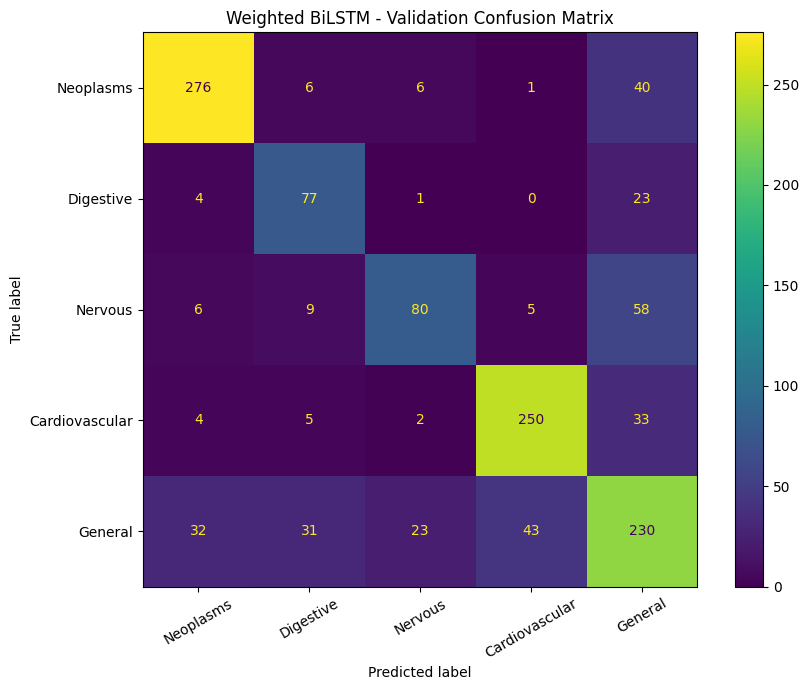

In [ ]:
weighted_bilstm_model.load_state_dict(best_weighted_bilstm_state)
weighted_bilstm_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for x_batch, lengths, y_batch in bilstm_val_loader:

        x_batch = x_batch.to(device)
        lengths = lengths.to(device)
        y_batch = y_batch.to(device)

        logits = weighted_bilstm_model(
            x_batch,
            lengths
        )

        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

all_preds_original = np.array(all_preds) + 1
all_labels_original = np.array(all_labels) + 1

print("WEIGHTED BiLSTM — BEST VALIDATION CHECKPOINT\n")

print(
    classification_report(
        all_labels_original,
        all_preds_original,
        digits=4
    )
)

cm = confusion_matrix(
    all_labels_original,
    all_preds_original
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Neoplasms",
        "Digestive",
        "Nervous",
        "Cardiovascular",
        "General"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=30)
plt.title("Weighted BiLSTM - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# PHASE 6 — BERT
# ==========================================================

## Objective
#Fine-tune a pretrained BERT model for five-class medical abstract classification
#and compare contextual transformer representations against classical ML,
#TextCNN, BiLSTM, and DistilBERT.

## First Step
#Analyze BERT tokenizer sequence lengths before selecting max_length.

In [ ]:
!pip install -q transformers datasets accelerate

In [ ]:
from transformers import AutoTokenizer
import numpy as np

BERT_CHECKPOINT = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_CHECKPOINT
)

token_lengths = []

for text in train_df["medical_abstract"].astype(str):
    ids = bert_tokenizer(
        text,
        add_special_tokens=True,
        truncation=False
    )["input_ids"]

    token_lengths.append(len(ids))

token_lengths = np.array(token_lengths)

print("BERT TOKEN LENGTH ANALYSIS")
print("-" * 45)
print("Count:", len(token_lengths))
print("Mean:", round(token_lengths.mean(), 2))
print("Median:", np.median(token_lengths))
print("75th percentile:", np.percentile(token_lengths, 75))
print("90th percentile:", np.percentile(token_lengths, 90))
print("95th percentile:", np.percentile(token_lengths, 95))
print("97.5th percentile:", np.percentile(token_lengths, 97.5))
print("99th percentile:", np.percentile(token_lengths, 99))
print("Maximum:", token_lengths.max())

print("\nPotential truncation:")
print("-" * 45)

for limit in [128, 256, 384, 512]:
    count = (token_lengths > limit).sum()
    pct = count / len(token_lengths) * 100
    print(f"> {limit:3d} tokens: {count:4d} abstracts ({pct:.2f}%)")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (545 > 512). Running this sequence through the model will result in indexing errors


BERT TOKEN LENGTH ANALYSIS
---------------------------------------------
Count: 5808
Mean: 281.42
Median: 272.0
75th percentile: 365.0
90th percentile: 441.3000000000002
95th percentile: 494.0
97.5th percentile: 555.0
99th percentile: 620.9300000000003
Maximum: 836

Potential truncation:
---------------------------------------------
> 128 tokens: 5182 abstracts (89.22%)
> 256 tokens: 3156 abstracts (54.34%)
> 384 tokens: 1192 abstracts (20.52%)
> 512 tokens:  232 abstracts (3.99%)


In [ ]:
from torch.utils.data import Dataset

BERT_MAX_LENGTH = 512

class BERTMedicalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.texts = dataframe["medical_abstract"].astype(str).tolist()
        self.labels = dataframe["condition_label"].astype(int).values - 1
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

bert_train_dataset = BERTMedicalDataset(
    train_df,
    bert_tokenizer,
    BERT_MAX_LENGTH
)

bert_val_dataset = BERTMedicalDataset(
    val_df,
    bert_tokenizer,
    BERT_MAX_LENGTH
)

print("Train examples:", len(bert_train_dataset))
print("Validation examples:", len(bert_val_dataset))
print("Max sequence length:", BERT_MAX_LENGTH)

Train examples: 5808
Validation examples: 1245
Max sequence length: 512


In [ ]:
from transformers import AutoModelForSequenceClassification

bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_CHECKPOINT,
    num_labels=5
).to(device)

print("Model:", BERT_CHECKPOINT)
print("Device:", device)

total_params = sum(p.numel() for p in bert_model.parameters())
trainable_params = sum(
    p.numel() for p in bert_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: bert-base-uncased
Device: cuda
Total parameters: 109,486,085
Trainable parameters: 109,486,085


In [ ]:
from torch.utils.data import DataLoader

BERT_BATCH_SIZE = 8

bert_train_loader = DataLoader(
    bert_train_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=True
)

bert_val_loader = DataLoader(
    bert_val_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(bert_train_loader))
print("Validation batches:", len(bert_val_loader))

Train batches: 726
Validation batches: 156


In [ ]:
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from copy import deepcopy
import torch

BERT_EPOCHS = 3

bert_optimizer = AdamW(
    bert_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

total_training_steps = (
    len(bert_train_loader) * BERT_EPOCHS
)

warmup_steps = int(
    0.1 * total_training_steps
)

bert_scheduler = get_linear_schedule_with_warmup(
    bert_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_bert_f1 = -1
best_bert_state = None

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Epochs:", BERT_EPOCHS)
print("Learning rate:", 2e-5)
print("Warmup steps:", warmup_steps)
print("Total training steps:", total_training_steps)

Epochs: 3
Learning rate: 2e-05
Warmup steps: 217
Total training steps: 2178


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

for epoch in range(BERT_EPOCHS):

    # -------------------------
    # TRAIN
    # -------------------------
    bert_model.train()

    total_train_loss = 0

    for batch in bert_train_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        bert_optimizer.zero_grad()

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):
            outputs = bert_model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(bert_optimizer)

        torch.nn.utils.clip_grad_norm_(
            bert_model.parameters(),
            max_norm=1.0
        )

        scaler.step(bert_optimizer)
        scaler.update()

        bert_scheduler.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(bert_train_loader)
    )

    # -------------------------
    # VALIDATION
    # -------------------------
    bert_model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for batch in bert_val_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available()
            ):
                outputs = bert_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_val_loss += outputs.loss.item()

            preds = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_val_loss = (
        total_val_loss / len(bert_val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    if val_macro_f1 > best_bert_f1:

        best_bert_f1 = val_macro_f1

        best_bert_state = deepcopy(
            bert_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{BERT_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest BERT Validation Macro F1:",
    round(best_bert_f1, 4)
)

Epoch 01/3 | Train Loss: 0.9028 | Val Loss: 0.6308 | Val Acc: 0.7831 | Val Macro F1: 0.7682
Epoch 02/3 | Train Loss: 0.4647 | Val Loss: 0.6216 | Val Acc: 0.7952 | Val Macro F1: 0.7920
Epoch 03/3 | Train Loss: 0.2877 | Val Loss: 0.6658 | Val Acc: 0.8153 | Val Macro F1: 0.8101

Best BERT Validation Macro F1: 0.8101


BERT — BEST VALIDATION CHECKPOINT

              precision    recall  f1-score   support

           1     0.8711    0.9240    0.8968       329
           2     0.7895    0.8571    0.8219       105
           3     0.7532    0.7342    0.7436       158
           4     0.8633    0.8810    0.8721       294
           5     0.7500    0.6852    0.7162       359

    accuracy                         0.8153      1245
   macro avg     0.8054    0.8163    0.8101      1245
weighted avg     0.8125    0.8153    0.8131      1245



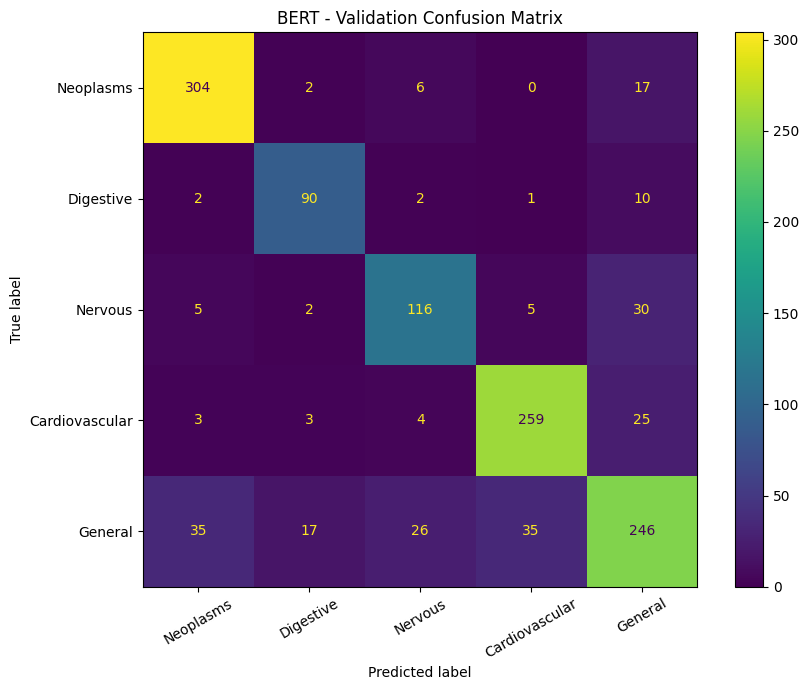

In [ ]:
bert_model.load_state_dict(best_bert_state)
bert_model.eval()

bert_preds = []
bert_labels = []

with torch.no_grad():
    for batch in bert_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(
            outputs.logits,
            dim=1
        )

        bert_preds.extend(
            preds.cpu().numpy()
        )

        bert_labels.extend(
            labels.cpu().numpy()
        )

bert_preds_original = np.array(bert_preds) + 1
bert_labels_original = np.array(bert_labels) + 1

print("BERT — BEST VALIDATION CHECKPOINT\n")

print(
    classification_report(
        bert_labels_original,
        bert_preds_original,
        digits=4
    )
)

cm = confusion_matrix(
    bert_labels_original,
    bert_preds_original
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Neoplasms",
        "Digestive",
        "Nervous",
        "Cardiovascular",
        "General"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=30)

plt.title("BERT - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# PHASE 7 — BioBERT
# ==========================================================

## Objective
#Test whether biomedical-domain pretraining improves medical abstract
#classification compared with the general BERT baseline.

## Comparison Baseline
#BERT validation Macro F1: 0.8124

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BIOBERT_CHECKPOINT = "dmis-lab/biobert-base-cased-v1.2"

biobert_tokenizer = AutoTokenizer.from_pretrained(
    BIOBERT_CHECKPOINT
)

biobert_model = AutoModelForSequenceClassification.from_pretrained(
    BIOBERT_CHECKPOINT,
    num_labels=5
).to(device)

print("Model:", BIOBERT_CHECKPOINT)
print("Device:", device)

total_params = sum(p.numel() for p in biobert_model.parameters())
trainable_params = sum(
    p.numel() for p in biobert_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `2`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those

Model: dmis-lab/biobert-base-cased-v1.2
Device: cuda
Total parameters: 108,314,117
Trainable parameters: 108,314,117


In [ ]:
biobert_lengths = []

for text in train_df["medical_abstract"].astype(str):
    ids = biobert_tokenizer(
        text,
        add_special_tokens=True,
        truncation=False
    )["input_ids"]

    biobert_lengths.append(len(ids))

biobert_lengths = np.array(biobert_lengths)

print("BIOBERT TOKEN LENGTH ANALYSIS")
print("-" * 45)
print("Mean:", round(biobert_lengths.mean(), 2))
print("Median:", np.median(biobert_lengths))
print("90th percentile:", np.percentile(biobert_lengths, 90))
print("95th percentile:", np.percentile(biobert_lengths, 95))
print("99th percentile:", np.percentile(biobert_lengths, 99))
print("Maximum:", biobert_lengths.max())

for limit in [256, 384, 512]:
    count = (biobert_lengths > limit).sum()
    pct = count / len(biobert_lengths) * 100
    print(f"> {limit} tokens: {count} abstracts ({pct:.2f}%)")

BIOBERT TOKEN LENGTH ANALYSIS
---------------------------------------------
Mean: 295.37
Median: 284.0
90th percentile: 465.0
95th percentile: 521.0
99th percentile: 648.9300000000003
Maximum: 880
> 256 tokens: 3397 abstracts (58.49%)
> 384 tokens: 1421 abstracts (24.47%)
> 512 tokens: 312 abstracts (5.37%)


In [ ]:
print("BioBERT num labels:", biobert_model.config.num_labels)

BioBERT num labels: 5


In [ ]:
BIOBERT_MAX_LENGTH = 512

class BioBERTMedicalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.texts = dataframe["medical_abstract"].astype(str).tolist()
        self.labels = dataframe["condition_label"].astype(int).values - 1
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long)
        }

biobert_train_dataset = BioBERTMedicalDataset(
    train_df,
    biobert_tokenizer,
    BIOBERT_MAX_LENGTH
)

biobert_val_dataset = BioBERTMedicalDataset(
    val_df,
    biobert_tokenizer,
    BIOBERT_MAX_LENGTH
)

print("Train examples:", len(biobert_train_dataset))
print("Validation examples:", len(biobert_val_dataset))
print("Max sequence length:", BIOBERT_MAX_LENGTH)

Train examples: 5808
Validation examples: 1245
Max sequence length: 512


In [ ]:
BIOBERT_BATCH_SIZE = 8

biobert_train_loader = DataLoader(
    biobert_train_dataset,
    batch_size=BIOBERT_BATCH_SIZE,
    shuffle=True
)

biobert_val_loader = DataLoader(
    biobert_val_dataset,
    batch_size=BIOBERT_BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(biobert_train_loader))
print("Validation batches:", len(biobert_val_loader))

Train batches: 726
Validation batches: 156


In [ ]:
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from copy import deepcopy
from sklearn.metrics import accuracy_score, f1_score
import torch

BIOBERT_EPOCHS = 3

biobert_optimizer = AdamW(
    biobert_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

total_training_steps = (
    len(biobert_train_loader) * BIOBERT_EPOCHS
)

warmup_steps = int(
    0.1 * total_training_steps
)

biobert_scheduler = get_linear_schedule_with_warmup(
    biobert_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_biobert_f1 = -1
best_biobert_state = None

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Epochs:", BIOBERT_EPOCHS)
print("Learning rate:", 2e-5)
print("Warmup steps:", warmup_steps)
print("Total training steps:", total_training_steps)

Epochs: 3
Learning rate: 2e-05
Warmup steps: 217
Total training steps: 2178


In [ ]:
for epoch in range(BIOBERT_EPOCHS):

    # -------------------------
    # TRAIN
    # -------------------------
    biobert_model.train()
    total_train_loss = 0

    for batch in biobert_train_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        biobert_optimizer.zero_grad()

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):
            outputs = biobert_model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(biobert_optimizer)

        torch.nn.utils.clip_grad_norm_(
            biobert_model.parameters(),
            max_norm=1.0
        )

        scaler.step(biobert_optimizer)
        scaler.update()

        biobert_scheduler.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(biobert_train_loader)
    )

    # -------------------------
    # VALIDATION
    # -------------------------
    biobert_model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for batch in biobert_val_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available()
            ):
                outputs = biobert_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_val_loss += outputs.loss.item()

            preds = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_val_loss = (
        total_val_loss / len(biobert_val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    if val_macro_f1 > best_biobert_f1:

        best_biobert_f1 = val_macro_f1

        best_biobert_state = deepcopy(
            biobert_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{BIOBERT_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest BioBERT Validation Macro F1:",
    round(best_biobert_f1, 4)
)

Epoch 01/3 | Train Loss: 0.7929 | Val Loss: 0.5126 | Val Acc: 0.8249 | Val Macro F1: 0.8166
Epoch 02/3 | Train Loss: 0.3804 | Val Loss: 0.5753 | Val Acc: 0.8394 | Val Macro F1: 0.8369
Epoch 03/3 | Train Loss: 0.2125 | Val Loss: 0.6295 | Val Acc: 0.8490 | Val Macro F1: 0.8456

Best BioBERT Validation Macro F1: 0.8456


BIOBERT — BEST VALIDATION CHECKPOINT

              precision    recall  f1-score   support

           1     0.9012    0.9149    0.9080       329
           2     0.8364    0.8762    0.8558       105
           3     0.7697    0.8038    0.7864       158
           4     0.9024    0.9116    0.9069       294
           5     0.7935    0.7493    0.7708       359

    accuracy                         0.8490      1245
   macro avg     0.8406    0.8511    0.8456      1245
weighted avg     0.8483    0.8490    0.8483      1245



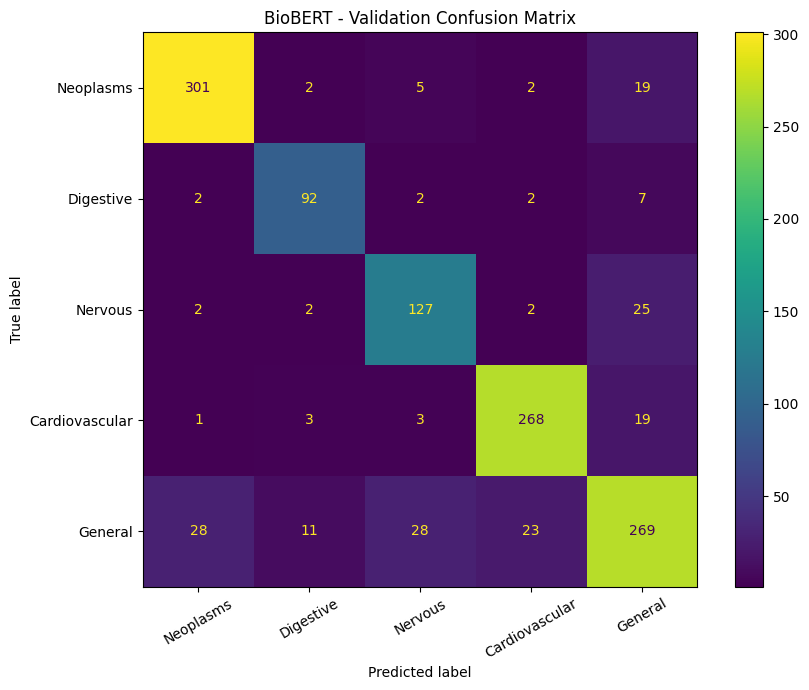

In [ ]:
biobert_model.load_state_dict(best_biobert_state)
biobert_model.eval()

biobert_preds = []
biobert_labels = []

with torch.no_grad():
    for batch in biobert_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = biobert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(
            outputs.logits,
            dim=1
        )

        biobert_preds.extend(
            preds.cpu().numpy()
        )

        biobert_labels.extend(
            labels.cpu().numpy()
        )

biobert_preds_original = np.array(biobert_preds) + 1
biobert_labels_original = np.array(biobert_labels) + 1

print("BIOBERT — BEST VALIDATION CHECKPOINT\n")

print(
    classification_report(
        biobert_labels_original,
        biobert_preds_original,
        digits=4
    )
)

cm = confusion_matrix(
    biobert_labels_original,
    biobert_preds_original
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Neoplasms",
        "Digestive",
        "Nervous",
        "Cardiovascular",
        "General"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=30)

plt.title("BioBERT - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
#biomert

In [ ]:
BIOMEDBERT_CHECKPOINT = "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BIOMEDBERT_CHECKPOINT = (
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"
)

biomedbert_tokenizer = AutoTokenizer.from_pretrained(
    BIOMEDBERT_CHECKPOINT
)

biomedbert_model = AutoModelForSequenceClassification.from_pretrained(
    BIOMEDBERT_CHECKPOINT,
    num_labels=5
).to(device)

print("Model:", BIOMEDBERT_CHECKPOINT)
print("Device:", device)

total_params = sum(
    p.numel()
    for p in biomedbert_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in biomedbert_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect ide

Model: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Device: cuda
Total parameters: 109,486,085
Trainable parameters: 109,486,085


In [ ]:
biomedbert_lengths = []

for text in train_df["medical_abstract"].astype(str):
    ids = biomedbert_tokenizer(
        text,
        add_special_tokens=True,
        truncation=False
    )["input_ids"]

    biomedbert_lengths.append(len(ids))

biomedbert_lengths = np.array(biomedbert_lengths)

print("BIOMEDBERT TOKEN LENGTH ANALYSIS")
print("-" * 45)

print("Count:", len(biomedbert_lengths))
print("Mean:", round(biomedbert_lengths.mean(), 2))
print("Median:", np.median(biomedbert_lengths))
print("75th percentile:", np.percentile(biomedbert_lengths, 75))
print("90th percentile:", np.percentile(biomedbert_lengths, 90))
print("95th percentile:", np.percentile(biomedbert_lengths, 95))
print("97.5th percentile:", np.percentile(biomedbert_lengths, 97.5))
print("99th percentile:", np.percentile(biomedbert_lengths, 99))
print("Maximum:", biomedbert_lengths.max())

print("\nPotential truncation:")
print("-" * 45)

for limit in [256, 384, 512]:
    count = (biomedbert_lengths > limit).sum()
    pct = count / len(biomedbert_lengths) * 100

    print(
        f"> {limit:3d} tokens: "
        f"{count:4d} abstracts "
        f"({pct:.2f}%)"
    )

BIOMEDBERT TOKEN LENGTH ANALYSIS
---------------------------------------------
Count: 5808
Mean: 238.2
Median: 229.0
75th percentile: 309.0
90th percentile: 373.0
95th percentile: 418.0
97.5th percentile: 474.0
99th percentile: 525.0
Maximum: 791

Potential truncation:
---------------------------------------------
> 256 tokens: 2344 abstracts (40.36%)
> 384 tokens:  493 abstracts (8.49%)
> 512 tokens:   79 abstracts (1.36%)


In [ ]:
BIOMEDBERT_MAX_LENGTH = 512

class BiomedBERTMedicalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.texts = dataframe["medical_abstract"].astype(str).tolist()
        self.labels = dataframe["condition_label"].astype(int).values - 1
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

biomedbert_train_dataset = BiomedBERTMedicalDataset(
    train_df,
    biomedbert_tokenizer,
    BIOMEDBERT_MAX_LENGTH
)

biomedbert_val_dataset = BiomedBERTMedicalDataset(
    val_df,
    biomedbert_tokenizer,
    BIOMEDBERT_MAX_LENGTH
)

BIOMEDBERT_BATCH_SIZE = 8

biomedbert_train_loader = DataLoader(
    biomedbert_train_dataset,
    batch_size=BIOMEDBERT_BATCH_SIZE,
    shuffle=True
)

biomedbert_val_loader = DataLoader(
    biomedbert_val_dataset,
    batch_size=BIOMEDBERT_BATCH_SIZE,
    shuffle=False
)

print("Train examples:", len(biomedbert_train_dataset))
print("Validation examples:", len(biomedbert_val_dataset))
print("Train batches:", len(biomedbert_train_loader))
print("Validation batches:", len(biomedbert_val_loader))
print("Max sequence length:", BIOMEDBERT_MAX_LENGTH)

Train examples: 5808
Validation examples: 1245
Train batches: 726
Validation batches: 156
Max sequence length: 512


In [ ]:
BIOMEDBERT_EPOCHS = 3

biomedbert_optimizer = AdamW(
    biomedbert_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

total_training_steps = (
    len(biomedbert_train_loader) * BIOMEDBERT_EPOCHS
)

warmup_steps = int(
    0.1 * total_training_steps
)

biomedbert_scheduler = get_linear_schedule_with_warmup(
    biomedbert_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_biomedbert_f1 = -1
best_biomedbert_state = None

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Epochs:", BIOMEDBERT_EPOCHS)
print("Learning rate:", 2e-5)
print("Warmup steps:", warmup_steps)
print("Total training steps:", total_training_steps)

Epochs: 3
Learning rate: 2e-05
Warmup steps: 217
Total training steps: 2178


In [ ]:
for epoch in range(BIOMEDBERT_EPOCHS):

    # -------------------------
    # TRAIN
    # -------------------------
    biomedbert_model.train()
    total_train_loss = 0

    for batch in biomedbert_train_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        biomedbert_optimizer.zero_grad()

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):
            outputs = biomedbert_model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(biomedbert_optimizer)

        torch.nn.utils.clip_grad_norm_(
            biomedbert_model.parameters(),
            max_norm=1.0
        )

        scaler.step(biomedbert_optimizer)
        scaler.update()

        biomedbert_scheduler.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(biomedbert_train_loader)
    )

    # -------------------------
    # VALIDATION
    # -------------------------
    biomedbert_model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for batch in biomedbert_val_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available()
            ):
                outputs = biomedbert_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_val_loss += outputs.loss.item()

            preds = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_val_loss = (
        total_val_loss / len(biomedbert_val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    if val_macro_f1 > best_biomedbert_f1:

        best_biomedbert_f1 = val_macro_f1

        best_biomedbert_state = deepcopy(
            biomedbert_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{BIOMEDBERT_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest BiomedBERT Validation Macro F1:",
    round(best_biomedbert_f1, 4)
)

Epoch 01/3 | Train Loss: 0.7593 | Val Loss: 0.5185 | Val Acc: 0.8361 | Val Macro F1: 0.8252
Epoch 02/3 | Train Loss: 0.3584 | Val Loss: 0.5445 | Val Acc: 0.8546 | Val Macro F1: 0.8541
Epoch 03/3 | Train Loss: 0.2108 | Val Loss: 0.5576 | Val Acc: 0.8683 | Val Macro F1: 0.8660

Best BiomedBERT Validation Macro F1: 0.866


BIOMEDBERT — BEST VALIDATION CHECKPOINT

              precision    recall  f1-score   support

           1     0.9112    0.9362    0.9235       329
           2     0.8704    0.8952    0.8826       105
           3     0.8075    0.8228    0.8150       158
           4     0.8921    0.9558    0.9228       294
           5     0.8297    0.7465    0.7859       359

    accuracy                         0.8683      1245
   macro avg     0.8622    0.8713    0.8660      1245
weighted avg     0.8666    0.8683    0.8665      1245



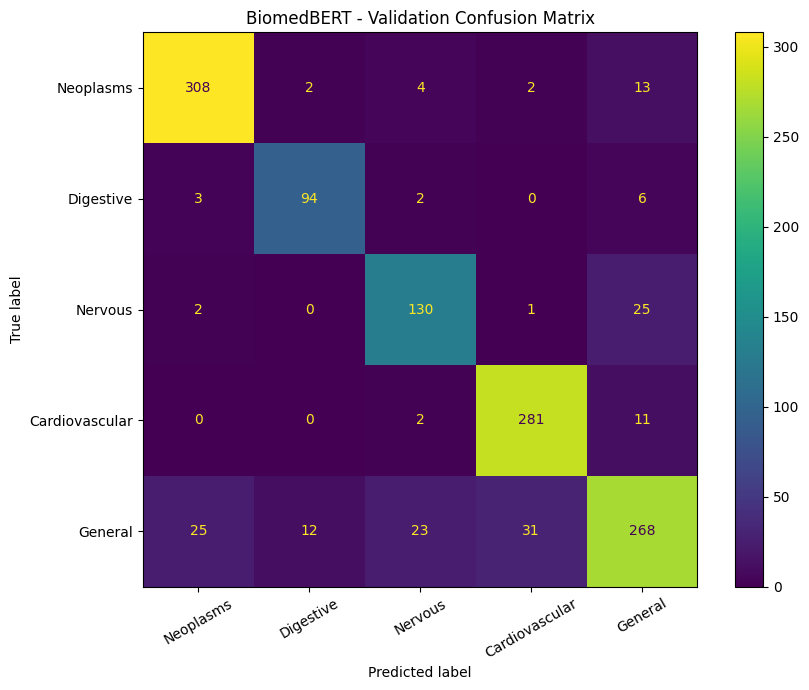

In [ ]:
biomedbert_model.load_state_dict(best_biomedbert_state)
biomedbert_model.eval()

biomedbert_preds = []
biomedbert_labels = []

with torch.no_grad():
    for batch in biomedbert_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = biomedbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(
            outputs.logits,
            dim=1
        )

        biomedbert_preds.extend(
            preds.cpu().numpy()
        )

        biomedbert_labels.extend(
            labels.cpu().numpy()
        )

biomedbert_preds_original = np.array(biomedbert_preds) + 1
biomedbert_labels_original = np.array(biomedbert_labels) + 1

print("BIOMEDBERT — BEST VALIDATION CHECKPOINT\n")

print(
    classification_report(
        biomedbert_labels_original,
        biomedbert_preds_original,
        digits=4
    )
)

cm = confusion_matrix(
    biomedbert_labels_original,
    biomedbert_preds_original
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Neoplasms",
        "Digestive",
        "Nervous",
        "Cardiovascular",
        "General"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=30)

plt.title("BiomedBERT - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# PHASE 9 — DeBERTa-v3
# ==========================================================

## Objective
#Evaluate whether a modern transformer architecture can outperform
#BERT and compete with biomedical-specific transformers.

## Current Best
#BiomedBERT Validation Macro F1: 0.8660

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"

deberta_tokenizer = AutoTokenizer.from_pretrained(
    DEBERTA_CHECKPOINT
)

deberta_model = AutoModelForSequenceClassification.from_pretrained(
    DEBERTA_CHECKPOINT,
    num_labels=5
).to(device)

print("Model:", DEBERTA_CHECKPOINT)
print("Device:", device)

total_params = sum(
    p.numel()
    for p in deberta_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in deberta_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.den

Model: microsoft/deberta-v3-base
Device: cuda
Total parameters: 184,425,989
Trainable parameters: 184,425,989


In [ ]:
deberta_lengths = []

for text in train_df["medical_abstract"].astype(str):

    ids = deberta_tokenizer(
        text,
        add_special_tokens=True,
        truncation=False
    )["input_ids"]

    deberta_lengths.append(len(ids))

deberta_lengths = np.array(deberta_lengths)

print("DEBERTA TOKEN LENGTH ANALYSIS")
print("-" * 45)

print("Count:", len(deberta_lengths))
print("Mean:", round(deberta_lengths.mean(), 2))
print("Median:", np.median(deberta_lengths))
print("75th percentile:", np.percentile(deberta_lengths, 75))
print("90th percentile:", np.percentile(deberta_lengths, 90))
print("95th percentile:", np.percentile(deberta_lengths, 95))
print("97.5th percentile:", np.percentile(deberta_lengths, 97.5))
print("99th percentile:", np.percentile(deberta_lengths, 99))
print("Maximum:", deberta_lengths.max())

print("\nPotential truncation:")
print("-" * 45)

for limit in [256, 384, 512]:
    count = (deberta_lengths > limit).sum()
    pct = count / len(deberta_lengths) * 100

    print(
        f"> {limit:3d} tokens: "
        f"{count:4d} abstracts "
        f"({pct:.2f}%)"
    )

DEBERTA TOKEN LENGTH ANALYSIS
---------------------------------------------
Count: 5808
Mean: 242.33
Median: 234.0
75th percentile: 315.0
90th percentile: 383.0
95th percentile: 428.64999999999964
97.5th percentile: 484.0
99th percentile: 539.0
Maximum: 792

Potential truncation:
---------------------------------------------
> 256 tokens: 2453 abstracts (42.23%)
> 384 tokens:  559 abstracts (9.62%)
> 512 tokens:   93 abstracts (1.60%)


In [ ]:
DEBERTA_MAX_LENGTH = 512

class DeBERTaMedicalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.texts = dataframe["medical_abstract"].astype(str).tolist()
        self.labels = dataframe["condition_label"].astype(int).values - 1
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

deberta_train_dataset = DeBERTaMedicalDataset(
    train_df,
    deberta_tokenizer,
    DEBERTA_MAX_LENGTH
)

deberta_val_dataset = DeBERTaMedicalDataset(
    val_df,
    deberta_tokenizer,
    DEBERTA_MAX_LENGTH
)

DEBERTA_BATCH_SIZE = 8

deberta_train_loader = DataLoader(
    deberta_train_dataset,
    batch_size=DEBERTA_BATCH_SIZE,
    shuffle=True
)

deberta_val_loader = DataLoader(
    deberta_val_dataset,
    batch_size=DEBERTA_BATCH_SIZE,
    shuffle=False
)

print("Train examples:", len(deberta_train_dataset))
print("Validation examples:", len(deberta_val_dataset))
print("Train batches:", len(deberta_train_loader))
print("Validation batches:", len(deberta_val_loader))
print("Max sequence length:", DEBERTA_MAX_LENGTH)

Train examples: 5808
Validation examples: 1245
Train batches: 726
Validation batches: 156
Max sequence length: 512


In [ ]:
DEBERTA_EPOCHS = 3

deberta_optimizer = AdamW(
    deberta_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

total_training_steps = (
    len(deberta_train_loader) * DEBERTA_EPOCHS
)

warmup_steps = int(
    0.1 * total_training_steps
)

deberta_scheduler = get_linear_schedule_with_warmup(
    deberta_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_deberta_f1 = -1
best_deberta_state = None

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Epochs:", DEBERTA_EPOCHS)
print("Learning rate:", 2e-5)
print("Warmup steps:", warmup_steps)
print("Total training steps:", total_training_steps)

Epochs: 3
Learning rate: 2e-05
Warmup steps: 217
Total training steps: 2178


In [ ]:
print("Model parameter dtype:", next(deberta_model.parameters()).dtype)

Model parameter dtype: torch.float16


In [ ]:
# Force model parameters to FP32
deberta_model = deberta_model.float().to(device)

print("New model dtype:", next(deberta_model.parameters()).dtype)

DEBERTA_EPOCHS = 3

deberta_optimizer = AdamW(
    deberta_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

total_training_steps = (
    len(deberta_train_loader) * DEBERTA_EPOCHS
)

warmup_steps = int(0.1 * total_training_steps)

deberta_scheduler = get_linear_schedule_with_warmup(
    deberta_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_deberta_f1 = -1
best_deberta_state = None

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

print("Ready.")
print("Epochs:", DEBERTA_EPOCHS)
print("Learning rate:", 2e-5)
print("Warmup steps:", warmup_steps)
print("Total training steps:", total_training_steps)

New model dtype: torch.float32
Ready.
Epochs: 3
Learning rate: 2e-05
Warmup steps: 217
Total training steps: 2178


In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

DEBERTA_BATCH_SIZE = 4

deberta_train_loader = DataLoader(
    deberta_train_dataset,
    batch_size=DEBERTA_BATCH_SIZE,
    shuffle=True
)

deberta_val_loader = DataLoader(
    deberta_val_dataset,
    batch_size=DEBERTA_BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(deberta_train_loader))
print("Validation batches:", len(deberta_val_loader))

Train batches: 1452
Validation batches: 312


In [ ]:
DEBERTA_EPOCHS = 3

deberta_optimizer = AdamW(
    deberta_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

total_training_steps = (
    len(deberta_train_loader) * DEBERTA_EPOCHS
)

warmup_steps = int(0.1 * total_training_steps)

deberta_scheduler = get_linear_schedule_with_warmup(
    deberta_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_deberta_f1 = -1
best_deberta_state = None

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

print("Batch size:", DEBERTA_BATCH_SIZE)
print("Warmup steps:", warmup_steps)
print("Total training steps:", total_training_steps)

Batch size: 4
Warmup steps: 435
Total training steps: 4356


In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared.")

GPU cache cleared.


In [ ]:
del bert_model
del biobert_model
del biomedbert_model

gc.collect()
torch.cuda.empty_cache()

print("Old transformer models deleted and GPU memory cleared.")

Old transformer models deleted and GPU memory cleared.


In [ ]:
print(torch.cuda.memory_summary(device=None, abbreviated=True))

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 2            |        cudaMalloc retries: 14        |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |  14526 MiB |  14526 MiB |  56660 GiB |  56646 GiB |
|---------------------------------------------------------------------------|
| Active memory         |  14526 MiB |  14526 MiB |  56660 GiB |  56646 GiB |
|---------------------------------------------------------------------------|
| Requested memory      |  14314 MiB |  14314 MiB |  55940 GiB |  55926 GiB |
|---------------------------------------------------------------

In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

DEBERTA_BATCH_SIZE = 2

deberta_train_loader = DataLoader(
    deberta_train_dataset,
    batch_size=DEBERTA_BATCH_SIZE,
    shuffle=True
)

deberta_val_loader = DataLoader(
    deberta_val_dataset,
    batch_size=DEBERTA_BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(deberta_train_loader))
print("Validation batches:", len(deberta_val_loader))

Train batches: 2904
Validation batches: 623


In [ ]:
import gc
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from copy import deepcopy
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (5).csv
Saving validation.csv to validation (5).csv


In [ ]:
train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("validation.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)

Train: (5808, 4)
Validation: (1245, 4)


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"

deberta_tokenizer = AutoTokenizer.from_pretrained(
    DEBERTA_CHECKPOINT
)

deberta_model = AutoModelForSequenceClassification.from_pretrained(
    DEBERTA_CHECKPOINT,
    num_labels=5
)

# Important: keep parameters FP32
deberta_model = deberta_model.float().to(device)

print("Model:", DEBERTA_CHECKPOINT)
print("Model dtype:", next(deberta_model.parameters()).dtype)
print("Device:", next(deberta_model.parameters()).device)

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Model: microsoft/deberta-v3-base
Model dtype: torch.float32
Device: cuda:0


In [ ]:
DEBERTA_MAX_LENGTH = 512

class DeBERTaMedicalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.texts = dataframe["medical_abstract"].astype(str).tolist()
        self.labels = (
            dataframe["condition_label"].astype(int).values - 1
        )
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

deberta_train_dataset = DeBERTaMedicalDataset(
    train_df,
    deberta_tokenizer,
    DEBERTA_MAX_LENGTH
)

deberta_val_dataset = DeBERTaMedicalDataset(
    val_df,
    deberta_tokenizer,
    DEBERTA_MAX_LENGTH
)

In [ ]:
DEBERTA_BATCH_SIZE = 2

deberta_train_loader = DataLoader(
    deberta_train_dataset,
    batch_size=DEBERTA_BATCH_SIZE,
    shuffle=True
)

deberta_val_loader = DataLoader(
    deberta_val_dataset,
    batch_size=DEBERTA_BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(deberta_train_loader))
print("Validation batches:", len(deberta_val_loader))

Train batches: 2904
Validation batches: 623


In [ ]:
DEBERTA_EPOCHS = 3
GRAD_ACCUM_STEPS = 4

deberta_optimizer = AdamW(
    deberta_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

updates_per_epoch = int(
    np.ceil(
        len(deberta_train_loader) / GRAD_ACCUM_STEPS
    )
)

total_training_steps = (
    updates_per_epoch * DEBERTA_EPOCHS
)

warmup_steps = int(
    0.1 * total_training_steps
)

deberta_scheduler = get_linear_schedule_with_warmup(
    deberta_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

best_deberta_f1 = -1
best_deberta_state = None

print("Physical batch size:", DEBERTA_BATCH_SIZE)
print("Gradient accumulation:", GRAD_ACCUM_STEPS)
print(
    "Effective batch size:",
    DEBERTA_BATCH_SIZE * GRAD_ACCUM_STEPS
)
print("Epochs:", DEBERTA_EPOCHS)
print("Total optimizer steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Physical batch size: 2
Gradient accumulation: 4
Effective batch size: 8
Epochs: 3
Total optimizer steps: 2178
Warmup steps: 217


In [ ]:
for epoch in range(DEBERTA_EPOCHS):

    # ========================
    # TRAIN
    # ========================

    deberta_model.train()

    total_train_loss = 0

    deberta_optimizer.zero_grad(set_to_none=True)

    for step, batch in enumerate(deberta_train_loader):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        with torch.amp.autocast(
            "cuda",
            dtype=torch.float16
        ):

            outputs = deberta_model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            raw_loss = outputs.loss

            loss = raw_loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()

        total_train_loss += raw_loss.item()

        should_update = (
            (step + 1) % GRAD_ACCUM_STEPS == 0
            or
            (step + 1) == len(deberta_train_loader)
        )

        if should_update:

            scaler.unscale_(deberta_optimizer)

            torch.nn.utils.clip_grad_norm_(
                deberta_model.parameters(),
                max_norm=1.0
            )

            scaler.step(deberta_optimizer)
            scaler.update()

            deberta_optimizer.zero_grad(
                set_to_none=True
            )

            deberta_scheduler.step()

    avg_train_loss = (
        total_train_loss /
        len(deberta_train_loader)
    )

    # ========================
    # VALIDATION
    # ========================

    deberta_model.eval()

    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for batch in deberta_val_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.amp.autocast(
                "cuda",
                dtype=torch.float16
            ):

                outputs = deberta_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_val_loss += outputs.loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_val_loss = (
        total_val_loss /
        len(deberta_val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    if val_macro_f1 > best_deberta_f1:

        best_deberta_f1 = val_macro_f1

        best_deberta_state = deepcopy(
            deberta_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{DEBERTA_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print(
    "\nBest DeBERTa Validation Macro F1:",
    round(best_deberta_f1, 4)
)

Epoch 01/3 | Train Loss: 0.9974 | Val Loss: 0.7912 | Val Acc: 0.7598 | Val Macro F1: 0.7387
Epoch 02/3 | Train Loss: 0.5347 | Val Loss: 0.5949 | Val Acc: 0.8289 | Val Macro F1: 0.8284
Epoch 03/3 | Train Loss: 0.3988 | Val Loss: 0.6746 | Val Acc: 0.8313 | Val Macro F1: 0.8322

Best DeBERTa Validation Macro F1: 0.8322


DEBERTA-v3 — BEST VALIDATION CHECKPOINT

              precision    recall  f1-score   support

           1     0.8619    0.9483    0.9030       329
           2     0.8679    0.8762    0.8720       105
           3     0.7812    0.7911    0.7862       158
           4     0.8408    0.8980    0.8684       294
           5     0.7987    0.6741    0.7311       359

    accuracy                         0.8313      1245
   macro avg     0.8301    0.8375    0.8322      1245
weighted avg     0.8289    0.8313    0.8278      1245



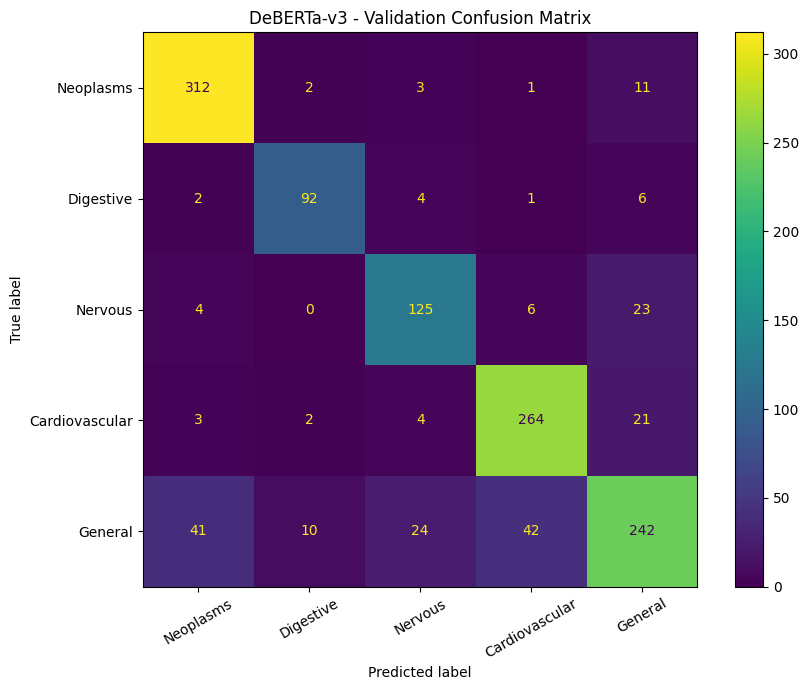

In [ ]:
deberta_model.load_state_dict(best_deberta_state)
deberta_model.eval()

deberta_preds = []
deberta_labels = []

with torch.no_grad():
    for batch in deberta_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        with torch.amp.autocast(
            "cuda",
            dtype=torch.float16
        ):
            outputs = deberta_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        preds = torch.argmax(
            outputs.logits,
            dim=1
        )

        deberta_preds.extend(
            preds.cpu().numpy()
        )

        deberta_labels.extend(
            labels.cpu().numpy()
        )

deberta_preds_original = np.array(deberta_preds) + 1
deberta_labels_original = np.array(deberta_labels) + 1

print("DEBERTA-v3 — BEST VALIDATION CHECKPOINT\n")

print(
    classification_report(
        deberta_labels_original,
        deberta_preds_original,
        digits=4
    )
)

cm = confusion_matrix(
    deberta_labels_original,
    deberta_preds_original
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Neoplasms",
        "Digestive",
        "Nervous",
        "Cardiovascular",
        "General"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=30)

plt.title("DeBERTa-v3 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()